# SimCLR & DeepCluster on CIFAR-10

**Task:** Implement SimCLR & DeepCluster on the same backbone (ResNet-18) and analyze.

**Analysis:**
- Inspect the role of augmentations, training duration, batch size
- Compare the performance of the two models

**Backbone:** ResNet-18 (modified for 32×32 CIFAR-10 inputs)

In [4]:
import wandb

## 1. Setup & Download CIFAR-10

In [5]:
import os, hashlib, urllib.request
from tqdm.auto import tqdm

# Store data under the home directory (e.g. /home/<user>/data/cifar on Ubuntu)
DATA_HOME = os.path.expanduser('~/data/cifar')
DATASET_DIR = os.path.join(DATA_HOME, 'dataset')
CIFAR_URL = 'https://data.brainchip.com/dataset-mirror/cifar10/cifar-10-python.tar.gz'
CIFAR_MD5 = 'c58f30108f718f92721af3b95e74349a'  # checksum of the official archive
tar_path = os.path.join(DATASET_DIR, 'cifar-10-python.tar.gz')

def md5sum(path, chunk_size=1 << 20):
    h = hashlib.md5()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(chunk_size), b''):
            h.update(chunk)
    return h.hexdigest()

os.makedirs(DATASET_DIR, exist_ok=True)
if os.path.exists(tar_path) and md5sum(tar_path) != CIFAR_MD5:
    print(f'Checksum mismatch, re-downloading: {tar_path}')
    os.remove(tar_path)

if not os.path.exists(tar_path):
    part_path = tar_path + '.part'
    try:
        with tqdm(unit='B', unit_scale=True, unit_divisor=1024, desc='CIFAR-10') as bar:
            def hook(blocks, block_size, total):
                bar.total = total
                bar.update(blocks * block_size - bar.n)
            urllib.request.urlretrieve(CIFAR_URL, part_path, reporthook=hook)
        if md5sum(part_path) != CIFAR_MD5:
            raise ValueError(f'Checksum mismatch for archive downloaded from {CIFAR_URL}')
    except Exception:
        if os.path.exists(part_path):
            os.remove(part_path)
        raise
    os.replace(part_path, tar_path)
    print(f'Saved to {tar_path}')
else:
    print(f'Archive already present: {tar_path}')


Archive already present: /home/lone-warrior/data/cifar/dataset/cifar-10-python.tar.gz


### 1.1 Convert CIFAR-10 Python Batches to Image Folders

The CIFAR-10 archive is downloaded from the BrainChip mirror (verified against the official MD5 checksum) and extracted to `~/data/cifar/dataset/cifar-10-batches-py/`. It contains the pickled batches `data_batch_1 … data_batch_5` (50k training images) and `test_batch` (10k test images), plus `batches.meta` with the class names.

The rest of the notebook expects class-wise image folders (`train/<class>/*.png` and `test/<class>/*.png`), so the cell below unpacks every batch into `~/data/cifar/cifar10/train/` and `~/data/cifar/cifar10/test/`. This cell is idempotent — it skips the conversion if the folders already exist.

In [6]:
import os, pickle, tarfile
import numpy as np
from collections import Counter
from tqdm.auto import tqdm
from PIL import Image

# --- Configuration ---
DATASET_DIR = os.path.join(DATA_HOME, 'dataset')
CIFAR_DIR = os.path.join(DATASET_DIR, 'cifar-10-batches-py')
DATA_ROOT = os.path.join(DATA_HOME, 'cifar10')
TRAIN_DIR = os.path.join(DATA_ROOT, 'train')
TEST_DIR = os.path.join(DATA_ROOT, 'test')

# Extract the archive if the pickled batches are not present yet
if not os.path.isdir(CIFAR_DIR):
    tar_path = os.path.join(DATASET_DIR, 'cifar-10-python.tar.gz')
    print(f'Extracting {tar_path} ...')
    with tarfile.open(tar_path, 'r:gz') as tf:
        tf.extractall(DATASET_DIR, filter='data')
    print('Done!')

def unpickle(file_path):
    with open(file_path, 'rb') as fo:
        return pickle.load(fo, encoding='bytes')

label_names = [n.decode('utf-8') for n in
               unpickle(os.path.join(CIFAR_DIR, 'batches.meta'))[b'label_names']]
print(f'Classes ({len(label_names)}): {label_names}')

def load_batches(batch_files):
    """Concatenate pickled CIFAR-10 batches into image and label arrays."""
    images, labels = [], []
    for name in batch_files:
        batch = unpickle(os.path.join(CIFAR_DIR, name))
        images.append(batch[b'data'])          # (N, 3072) uint8, channel-first
        labels.extend(batch[b'labels'])
    return np.concatenate(images, axis=0), np.array(labels)

def dump_images(images, labels, split_dir):
    """Write uint8 CIFAR images (N, 3, 32, 32) as class-wise PNG folders."""
    class_dirs = {}
    for label, cls in enumerate(label_names):
        class_dirs[label] = os.path.join(split_dir, cls)
        os.makedirs(class_dirs[label], exist_ok=True)

    counters = Counter()
    for img, label in zip(images, labels):
        out_path = os.path.join(class_dirs[label], f'{counters[label]:05d}.png')
        Image.fromarray(img.reshape(3, 32, 32).transpose(1, 2, 0)).save(out_path)
        counters[label] += 1

def count_images(split_dir):
    if not os.path.isdir(split_dir):
        return 0
    return sum(len(os.listdir(os.path.join(split_dir, c)))
               for c in os.listdir(split_dir))

# Only convert if the resulting image folders are not already complete
if count_images(TRAIN_DIR) != 50000 or count_images(TEST_DIR) != 10000:
    print('Converting training batches (data_batch_1 ... data_batch_5) ...')
    train_images, train_labels = load_batches([f'data_batch_{i}' for i in range(1, 6)])
    dump_images(train_images, train_labels, TRAIN_DIR)
    print(f'Train: {len(train_images)} images -> {TRAIN_DIR}')

    print('Converting test batch (test_batch) ...')
    test_images, test_labels = load_batches(['test_batch'])
    dump_images(test_images, test_labels, TEST_DIR)
    print(f'Test: {len(test_images)} images -> {TEST_DIR}')
else:
    print('Converted image folders already exist — skipping.')

# Verify
for split in ['train', 'test']:
    path = os.path.join(DATA_ROOT, split)
    classes = sorted([d for d in os.listdir(path) if not d.startswith('.')])
    total = sum(len(os.listdir(os.path.join(path, c))) for c in classes)
    print(f'{split}: {total} images across {len(classes)} classes')


Classes (10): ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Converted image folders already exist — skipping.
train: 50000 images across 10 classes
test: 10000 images across 10 classes


### 1.2 Imports & Device Check

In [7]:
import os
import copy
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from collections import Counter

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, Subset
import torchvision
import torchvision.transforms as transforms
import kornia.augmentation as K
from torchvision.models import resnet18

from sklearn.cluster import KMeans
from scipy.optimize import linear_sum_assignment

# Check GPU availability
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')

torch.backends.cudnn.benchmark = True

Using device: cuda
GPU: NVIDIA GeForce RTX 5080 Laptop GPU


## 2. Dataset Exploration

The CIFAR-10 dataset is organized class-wise under `cifar10/train/` and `cifar10/test/` directories. Each class folder contains PNG images of size 32×32.

In [8]:
# Path to the dataset converted from the CIFAR-10 python batches (see section 1.1)
DATA_ROOT = os.path.join(DATA_HOME, 'cifar10')
TRAIN_DIR = os.path.join(DATA_ROOT, 'train')
TEST_DIR = os.path.join(DATA_ROOT, 'test')

# List classes
classes = sorted(os.listdir(TRAIN_DIR))
classes = [c for c in classes if not c.startswith('.')]  # filter hidden files
print(f'Classes ({len(classes)}): {classes}')

Classes (10): ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [9]:
# Count images per class in train and test
print('=== Training Set ===')
total_train = 0
for cls in classes:
    n = len(os.listdir(os.path.join(TRAIN_DIR, cls)))
    print(f'  {cls:>12s}: {n:5d} images')
    total_train += n
print(f'  {"TOTAL":>12s}: {total_train:5d} images')

print('\n=== Test Set ===')
total_test = 0
for cls in classes:
    n = len(os.listdir(os.path.join(TEST_DIR, cls)))
    print(f'  {cls:>12s}: {n:5d} images')
    total_test += n
print(f'  {"TOTAL":>12s}: {total_test:5d} images')

=== Training Set ===
      airplane:  5000 images
    automobile:  5000 images
          bird:  5000 images
           cat:  5000 images
          deer:  5000 images
           dog:  5000 images
          frog:  5000 images
         horse:  5000 images
          ship:  5000 images
         truck:  5000 images
         TOTAL: 50000 images

=== Test Set ===
      airplane:  1000 images
    automobile:  1000 images
          bird:  1000 images
           cat:  1000 images
          deer:  1000 images
           dog:  1000 images
          frog:  1000 images
         horse:  1000 images
          ship:  1000 images
         truck:  1000 images
         TOTAL: 10000 images


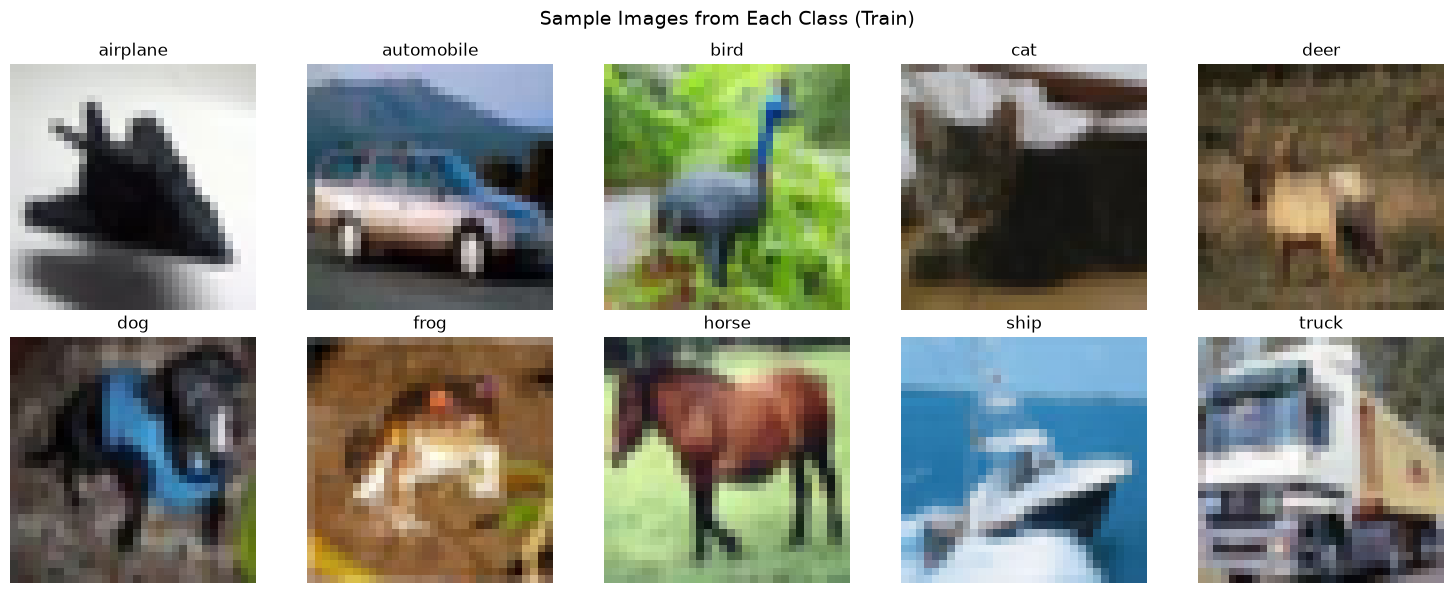

Image size: (32, 32)
Image mode: RGB


In [10]:
# Visualize a few sample images from each class
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for idx, cls in enumerate(classes):
    ax = axes[idx // 5, idx % 5]
    cls_dir = os.path.join(TRAIN_DIR, cls)
    img_name = sorted(os.listdir(cls_dir))[0]
    img = Image.open(os.path.join(cls_dir, img_name))
    ax.imshow(img)
    ax.set_title(cls, fontsize=12)
    ax.axis('off')
plt.suptitle('Sample Images from Each Class (Train)', fontsize=14)
plt.tight_layout()
plt.show()

# Check image size
sample_img = Image.open(os.path.join(TRAIN_DIR, classes[0], sorted(os.listdir(os.path.join(TRAIN_DIR, classes[0])))[0]))
print(f'Image size: {sample_img.size}')
print(f'Image mode: {sample_img.mode}')

## 3. Load the Dataset onto the GPU and Create Loaders

CIFAR-10 is tiny (50k + 10k images of 32×32×3 bytes ≈ 180 MB as `uint8`), so the whole dataset is read from the pickled batches straight into GPU memory once. `GPULoader` then serves batches directly from GPU memory, so there are no DataLoader worker processes and no per-image file reads. For now only normalization is applied; the SimCLR/DeepCluster augmentations are defined later and also run on the GPU.

In [11]:
# CIFAR-10 normalization statistics
CIFAR10_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR10_STD = (0.2470, 0.2435, 0.2616)

# Load the whole dataset from the pickled batches (see section 1.1) into GPU
# memory as uint8. Labels are tiny and stay on the CPU.
def load_cifar_to_device(batch_files):
    images, labels = load_batches(batch_files)   # (N, 3072) uint8, (N,)
    images = torch.from_numpy(images).view(-1, 3, 32, 32).to(device)
    return images, torch.from_numpy(labels).long()

train_x, train_y = load_cifar_to_device([f'data_batch_{i}' for i in range(1, 6)])
test_x, test_y = load_cifar_to_device(['test_batch'])


class GPULoader:
    """Drop-in replacement for a DataLoader over images that already live on the GPU.

    Yields `(images, labels)` (or just `images` if `labels` is None). Images are
    converted to float in [0, 1] and passed through `transform`, which runs on
    the GPU; if `transform` returns a tuple (e.g. two SimCLR views) it is
    yielded as is. Labels are CPU tensors.
    """
    def __init__(self, images, labels=None, batch_size=256, shuffle=False,
                 drop_last=False, transform=None):
        self.images, self.labels = images, labels
        self.batch_size, self.shuffle = batch_size, shuffle
        self.drop_last, self.transform = drop_last, transform

    def __len__(self):
        n = len(self.images)
        return n // self.batch_size if self.drop_last else -(-n // self.batch_size)

    def __iter__(self):
        n = len(self.images)
        order = torch.randperm(n) if self.shuffle else torch.arange(n)
        for start in range(0, len(self) * self.batch_size, self.batch_size):
            idx = order[start:start + self.batch_size]
            x = self.images[idx.to(self.images.device)].float().div_(255)
            if self.transform is not None:
                with torch.no_grad():
                    x = self.transform(x)
            yield x if self.labels is None else (x, self.labels[idx])


# Base transform (no augmentation — used for evaluation / linear probing)
base_transform = transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD)

print(f'Train: {tuple(train_x.shape)} {train_x.dtype} on {train_x.device}')
print(f'Test:  {tuple(test_x.shape)} {test_x.dtype} on {test_x.device}')
print(f'Dataset size in GPU memory: {(train_x.numel() + test_x.numel()) / 2**20:.0f} MB')
print(f'Class-to-index mapping: {dict(zip(label_names, range(len(label_names))))}')


Train: (50000, 3, 32, 32) torch.uint8 on cuda:0
Test:  (10000, 3, 32, 32) torch.uint8 on cuda:0
Dataset size in GPU memory: 176 MB
Class-to-index mapping: {'airplane': 0, 'automobile': 1, 'bird': 2, 'cat': 3, 'deer': 4, 'dog': 5, 'frog': 6, 'horse': 7, 'ship': 8, 'truck': 9}


In [12]:
# Create loaders (served from GPU memory)
BATCH_SIZE = 256

train_loader = GPULoader(
    train_x, train_y,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True,
    transform=base_transform,
)

test_loader = GPULoader(
    test_x, test_y,
    batch_size=BATCH_SIZE,
    shuffle=False,
    transform=base_transform,
)

# Verify a batch
images, labels = next(iter(train_loader))
print(f'Batch shape: {images.shape}')   # Expected: [256, 3, 32, 32]
print(f'Labels shape: {labels.shape}')  # Expected: [256]
print(f'Label range: {labels.min().item()} – {labels.max().item()}')


Batch shape: torch.Size([256, 3, 32, 32])
Labels shape: torch.Size([256])
Label range: 0 – 9


## 4. ResNet-18 Backbone (Modified for CIFAR-10 32×32)

Standard ResNet-18 is designed for 224×224 ImageNet inputs. Its first layer uses a 7×7 conv with stride 2 followed by a 3×3 max-pool with stride 2, which aggressively downsamples the spatial dimensions.

For 32×32 CIFAR-10 images, this is too aggressive (the feature map would shrink to 1×1 too quickly). Following the instructor's advice, we **modify the network minimally**:
1. Replace `conv1` (7×7, stride=2) with a 3×3 conv, stride=1, padding=1
2. Remove the initial max-pooling layer

This is a standard and well-established modification (used in SimCLR / BYOL / MoCo papers when working with CIFAR). We do NOT resize the images.

In [13]:
def get_resnet18_cifar(num_classes=10):
    """
    Returns a ResNet-18 model modified for 32x32 CIFAR-10 images.
    - No pretrained weights
    - conv1: 3x3 kernel, stride 1, padding 1 (instead of 7x7, stride 2)
    - Removes the initial max-pool layer
    """
    model = resnet18(weights=None)  # No pretrained weights

    # Modify conv1 for 32x32 inputs
    model.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)

    # Remove max pooling (replace with identity)
    model.maxpool = nn.Identity()

    # The feature dimension before the final FC layer
    feature_dim = model.fc.in_features  # 512
    print(f'Feature dimension (before FC): {feature_dim}')

    return model, feature_dim

In [14]:
# Instantiate the model and verify it works with CIFAR-10 sized inputs
model, feature_dim = get_resnet18_cifar()
model = model.to(device)

# Test forward pass with a dummy CIFAR-10 batch
dummy_input = torch.randn(4, 3, 32, 32).to(device)
with torch.no_grad():
    output = model(dummy_input)
print(f'Input shape:  {dummy_input.shape}')
print(f'Output shape: {output.shape}')  # Expected: [4, 1000] (default ImageNet head)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'\nTotal parameters:     {total_params:,}')
print(f'Trainable parameters: {trainable_params:,}')

Feature dimension (before FC): 512
Input shape:  torch.Size([4, 3, 32, 32])
Output shape: torch.Size([4, 1000])

Total parameters:     11,681,832
Trainable parameters: 11,681,832


In [15]:
# Print the modified architecture summary
print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): Identity()
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), p

---
**Checkpoint:** Dataset loaded, train/test splits created, ResNet-18 backbone (modified for CIFAR-10) instantiated without pretrained weights. Ready to proceed with SimCLR and DeepCluster implementations.

## 5. SimCLR — Contrastive Self-Supervised Learning

SimCLR (Chen et al., 2020) learns visual representations by maximizing agreement between two randomly augmented views of the same image via a contrastive loss (NT-Xent).

**Key components:**
1. **Stochastic Data Augmentation:** Two correlated views of each image via random crop, color jitter, horizontal flip, and grayscale
2. **Encoder (f):** ResNet-18 backbone → feature vector h
3. **Projection Head (g):** MLP (2-layer) that maps h → z (used only during contrastive training)
4. **NT-Xent Loss:** Normalized temperature-scaled cross-entropy loss over cosine similarities

### 5.1 SimCLR Augmentation Pipeline

In [16]:
def build_gpu_transform(crop=True, jitter=True, grayscale=True, s=1.0, size=32):
    """SimCLR-style augmentation that runs on a batch of images on the GPU.

    Input: float images in [0, 1], shape (B, 3, H, W). Kornia samples the random
    parameters independently for every image in the batch. Output is normalized.
    """
    ops = []
    if crop:
        ops.append(K.RandomResizedCrop((size, size), scale=(0.2, 1.0)))
    ops.append(K.RandomHorizontalFlip())
    if jitter:
        ops.append(K.ColorJitter(0.4*s, 0.4*s, 0.4*s, 0.1*s, p=0.8))
    if grayscale:
        ops.append(K.RandomGrayscale(p=0.2))
    ops.append(K.Normalize(torch.tensor(CIFAR10_MEAN), torch.tensor(CIFAR10_STD)))
    return nn.Sequential(*ops).to(device)


class SimCLRAugmentation:
    """
    Produces two randomly augmented views of each image in a batch.
    Following the SimCLR paper: random crop + resize, color jitter,
    random horizontal flip, random grayscale (see build_gpu_transform).
    """
    def __init__(self, transform, size=32, s=0.5):
        self.transform = transform

    def __call__(self, x):
        return self.transform(x), self.transform(x)


def make_simclr_loader(augmentation, batch_size):
    """Loader yielding two augmented views per training image, all on the GPU."""
    return GPULoader(train_x, None, batch_size=batch_size, shuffle=True,
                     drop_last=True, transform=augmentation)


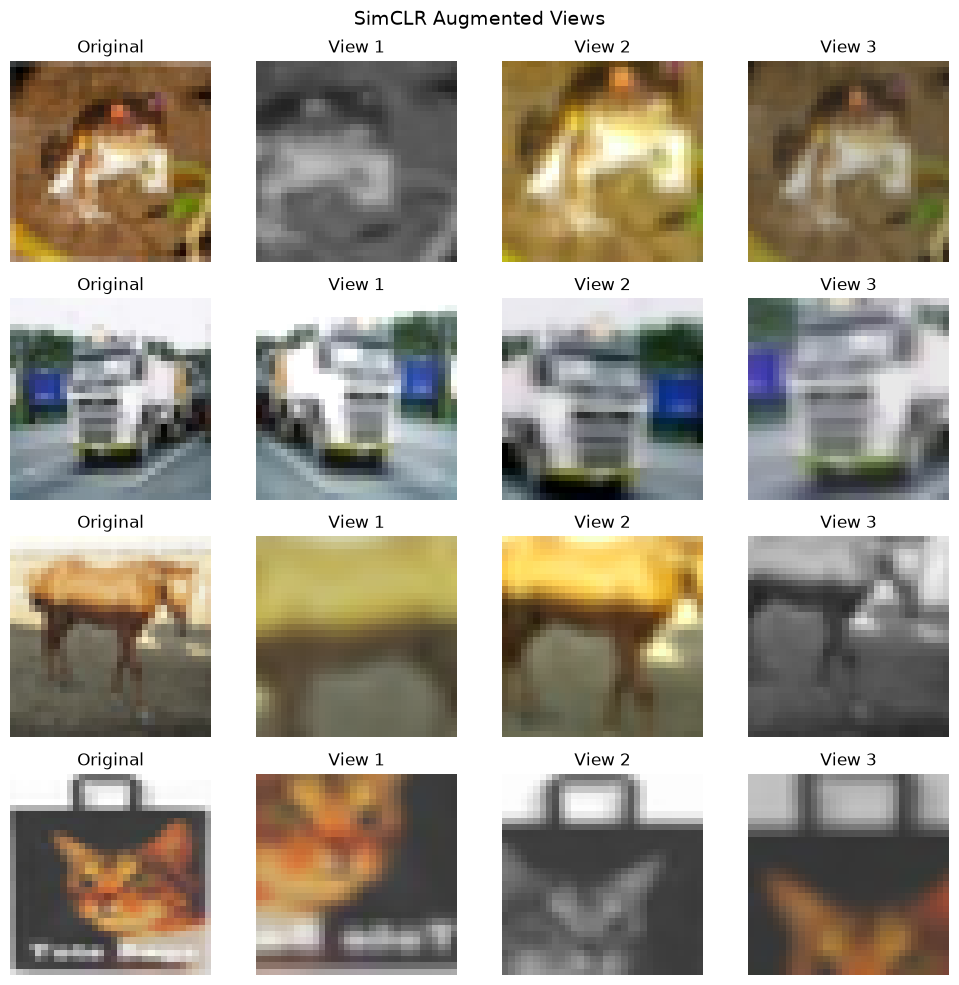

In [17]:
# Visualize augmented pairs
default_transform = build_gpu_transform(s=0.5)

simclr_aug = SimCLRAugmentation(default_transform , size=32)

def denorm(t):
    mean = torch.tensor(CIFAR10_MEAN, device=t.device).view(3,1,1)
    std = torch.tensor(CIFAR10_STD, device=t.device).view(3,1,1)
    return torch.clamp(t * std + mean, 0, 1)

def show(ax, t):
    ax.imshow(denorm(t[0]).permute(1,2,0).cpu().numpy())

fig, axes = plt.subplots(4, 4, figsize=(10, 10))
with torch.no_grad():
    for row in range(4):
        img_u8 = train_x[row * 1000]                       # (3, 32, 32) uint8 on the GPU
        img = img_u8.float().div(255).unsqueeze(0)
        v1, v2 = simclr_aug(img)
        axes[row, 0].imshow(img_u8.permute(1,2,0).cpu().numpy())
        axes[row, 0].set_title('Original')
        show(axes[row, 1], v1)
        axes[row, 1].set_title('View 1')
        show(axes[row, 2], v2)
        axes[row, 2].set_title('View 2')
        # Show another pair
        v3, v4 = simclr_aug(img)
        show(axes[row, 3], v3)
        axes[row, 3].set_title('View 3')
        for ax in axes[row]:
            ax.axis('off')
plt.suptitle('SimCLR Augmented Views', fontsize=14)
plt.tight_layout()
plt.show()


### 5.2 SimCLR Model (Encoder + Projection Head)

In [18]:
class SimCLRModel(nn.Module):
    """
    SimCLR model: ResNet-18 backbone + 2-layer MLP projection head.
    The projection head maps 512-d features to a lower-dimensional space
    where the contrastive loss is computed.
    """
    def __init__(self, feature_dim=512, projection_dim=128):
        super().__init__()
        # Backbone (encoder f)
        backbone, feat_dim = get_resnet18_cifar()
        # Remove the final FC layer — we'll use our own projection head
        self.encoder = nn.Sequential(*list(backbone.children())[:-1])  # up to avgpool

        # Projection head g(·): 2-layer MLP
        self.projection_head = nn.Sequential(
            nn.Linear(feat_dim, feat_dim),
            nn.ReLU(inplace=True),
            nn.Linear(feat_dim, projection_dim),
        )

    def forward(self, x):
        # Encode
        h = self.encoder(x)           # [B, 512, 1, 1]
        h = h.squeeze(-1).squeeze(-1)  # [B, 512]
        # Project
        z = self.projection_head(h)    # [B, projection_dim]
        return h, z

### 5.3 NT-Xent Loss (Normalized Temperature-Scaled Cross-Entropy)

In [19]:
class NTXentLoss(nn.Module):
    """
    NT-Xent loss for SimCLR.
    For a batch of N images, we get 2N augmented views.
    For each positive pair (i, i+N), the other 2(N-1) views are negatives.
    """
    def __init__(self, temperature=0.5):
        super().__init__()
        self.temperature = temperature
        self.criterion = nn.CrossEntropyLoss(reduction='mean')

    def forward(self, z1, z2):
        batch_size = z1.size(0)
        # L2 normalize
        z1 = F.normalize(z1, dim=1)
        z2 = F.normalize(z2, dim=1)

        # Concatenate: [z1_0, ..., z1_N-1, z2_0, ..., z2_N-1]
        z = torch.cat([z1, z2], dim=0)  # [2N, D]

        # Cosine similarity matrix [2N x 2N]
        sim_matrix = torch.mm(z, z.t()) / self.temperature  # [2N, 2N]

        # Mask out self-similarity (diagonal)
        mask = torch.eye(2 * batch_size, dtype=torch.bool, device=z.device)
        sim_matrix = sim_matrix.masked_fill(mask, -1e9)

        # Labels: positive pair for z1_i is z2_i and vice versa
        # For row i (i < N), positive is at column i + N
        # For row i (i >= N), positive is at column i - N
        labels = torch.cat([
            torch.arange(batch_size, 2 * batch_size),
            torch.arange(0, batch_size)
        ]).to(z.device)

        loss = self.criterion(sim_matrix, labels)
        return loss


### 5.4 SimCLR Training Loop

In [20]:
def train_simclr(model, train_loader, epochs=100, lr=3e-4, temperature=0.5,
                  weight_decay=1e-4, warmup_epochs=10,
                  transfer_to_device=True, non_blocking=True, device=None):
    """Train the SimCLR model.

    Parameters
    ----------
    transfer_to_device : bool
        Whether to move each mini-batch to the target device before forward pass.
    non_blocking : bool
        Whether to use non-blocking GPU transfer when available.
    device : torch.device or None
        Device to use. Defaults to the notebook's active device.
    """
    if device is None:
        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    model = model.to(device).float()
    model.train()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    def lr_lambda(epoch):
        if epoch < warmup_epochs:
            return epoch / warmup_epochs
        return 0.5 * (1 + np.cos(np.pi * (epoch - warmup_epochs) / (epochs - warmup_epochs)))
    scheduler = optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

    criterion = NTXentLoss(temperature=temperature)

    history = {'loss': [], 'lr': []}

    for epoch in tqdm(range(epochs), desc='SimCLR epochs'):
        total_loss = 0
        num_batches = 0
        batch_iterator = tqdm(
            train_loader,
            desc=f'Epoch {epoch + 1}/{epochs}',
            leave=False,
        )
        for view1, view2 in batch_iterator:
            if transfer_to_device:
                view1 = view1.to(device, non_blocking=non_blocking)
                view2 = view2.to(device, non_blocking=non_blocking)

            optimizer.zero_grad(set_to_none=True)

            _, z1 = model(view1)
            _, z2 = model(view2)
            loss = criterion(z1, z2)

            loss.backward()
            optimizer.step()

            total_loss += loss.detach().item()
            num_batches += 1
            batch_iterator.set_postfix(loss=f'{loss.detach().item():.4f}')

        scheduler.step()
        avg_loss = total_loss / num_batches
        current_lr = scheduler.get_last_lr()[0]
        history['loss'].append(avg_loss)
        history['lr'].append(current_lr)

        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f'Epoch [{epoch+1}/{epochs}]  Loss: {avg_loss:.4f}  LR: {current_lr:.6f}')

    return history


In [21]:
# Create SimCLR training loader (both views are augmented on the GPU)
simclr_aug = SimCLRAugmentation(default_transform)

SIMCLR_BATCH_SIZE = 256
simclr_loader = make_simclr_loader(simclr_aug, SIMCLR_BATCH_SIZE)
print(f'SimCLR training batches per epoch: {len(simclr_loader)}')


SimCLR training batches per epoch: 195


In [ ]:
# Train SimCLR
SIMCLR_EPOCHS = 1  # Compromise: 100 epochs (more would be better but limited resources)

simclr_model = SimCLRModel(feature_dim=512, projection_dim=128).to(device).float()
simclr_history = train_simclr(
    simclr_model, simclr_loader,
    epochs=SIMCLR_EPOCHS, lr=3e-4, temperature=0.5,
    weight_decay=1e-4, warmup_epochs=10,
    transfer_to_device=True,
    non_blocking=True,
    device=device,
)


Feature dimension (before FC): 512


SimCLR epochs:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch 1/1:   0%|          | 0/195 [00:00<?, ?it/s]

Epoch [1/1]  Loss: 6.1910  LR: 0.000030


### Accuracy Evaluation: Linear Classifier on Frozen Features

In [22]:
@torch.no_grad()
def extract_frozen_features(encoder, data_loader):
    """Extract encoder features without updating the pretrained model."""
    encoder.eval()
    features, labels = [], []
    for images, batch_labels in tqdm(data_loader, desc='Extracting features', leave=False):
        images = images.to(device)
        batch_features = encoder(images).flatten(1)
        features.append(batch_features.cpu())
        labels.append(batch_labels)
    return torch.cat(features), torch.cat(labels)


def train_linear_classifier(encoder, train_loader, test_loader,
                            feature_dim=512, num_classes=10,
                            epochs=100, lr=0.3,
                            return_final_accuracy=False):
    """Train and evaluate a linear classifier on frozen encoder features."""
    print('Extracting frozen train features...')
    train_features, train_labels = extract_frozen_features(encoder, train_loader)
    print('Extracting frozen test features...')
    test_features, test_labels = extract_frozen_features(encoder, test_loader)

    feature_train_loader = DataLoader(
        torch.utils.data.TensorDataset(train_features, train_labels),
        batch_size=512, shuffle=True,
    )
    feature_test_loader = DataLoader(
        torch.utils.data.TensorDataset(test_features, test_labels),
        batch_size=512, shuffle=False,
    )

    classifier = nn.Linear(feature_dim, num_classes).to(device)
    optimizer = optim.SGD(classifier.parameters(), lr=lr, momentum=0.9)
    criterion = nn.CrossEntropyLoss()
    best_test_accuracy = 0.0

    for epoch in range(epochs):
        classifier.train()
        for features, labels in feature_train_loader:
            features, labels = features.to(device), labels.to(device)
            loss = criterion(classifier(features), labels)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        classifier.eval()
        correct = total = 0
        with torch.no_grad():
            for features, labels in feature_test_loader:
                features, labels = features.to(device), labels.to(device)
                predictions = classifier(features).argmax(dim=1)
                correct += (predictions == labels).sum().item()
                total += labels.numel()
        test_accuracy = correct / total
        best_test_accuracy = max(best_test_accuracy, test_accuracy)

        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f'Epoch [{epoch + 1}/{epochs}]  Test Accuracy: '
                  f'{test_accuracy:.4f} ({test_accuracy * 100:.2f}%)')

    print(f'\nFinal Test Accuracy: {test_accuracy:.4f} '
          f'({test_accuracy * 100:.2f}%)')
    print(f'Best Test Accuracy: {best_test_accuracy:.4f} '
          f'({best_test_accuracy * 100:.2f}%)')
    if return_final_accuracy:
        return classifier, best_test_accuracy, test_accuracy
    return classifier, best_test_accuracy


# linear_classifier, simclr_test_accuracy = train_linear_classifier(
#     simclr_model.encoder,
#     train_loader,
#     test_loader,
#     feature_dim=512,
#     num_classes=len(classes),
#     epochs=100,
#     lr=0.3,
# )

### Role of Batch Size.

In [ ]:
try:
    import wandb
except ImportError:
    wandb = None


def finish_stale_wandb_run():
    """Close a wandb run left open by an interrupted cell, then make sure we're logged in.

    Interrupting the kernel also stops wandb's background process, so the old
    run can't be finished normally and the next wandb.init() fails with
    'Connection lost'. Tearing wandb down lets the next run start cleanly, but
    it also logs the session out, so log back in from ~/.netrc afterwards.
    """
    if wandb is None:
        return
    if wandb.run is not None:
        try:
            wandb.finish()
        except Exception:
            try:
                wandb.teardown()
            except Exception:
                pass
    wandb.login()


def run_batch_size_experiment(batch_sizes, epochs, project='simclr-batch-size',
                              wandb_logging=True, run_name='batch-size-comparison'):
    """Train SimCLR for each batch size and evaluate frozen features linearly."""
    batch_sizes = list(batch_sizes)
    if not batch_sizes or any(batch_size <= 0 for batch_size in batch_sizes):
        raise ValueError('batch_sizes must contain at least one positive integer.')
    if epochs <= 0:
        raise ValueError('epochs must be a positive integer.')
    if wandb_logging and wandb is None:
        raise ImportError('Install wandb or set wandb_logging=False.')

    results = {}
    if wandb_logging:
        finish_stale_wandb_run()
        wandb.init(
            project=project,
            name=run_name,
            config={
                'batch_sizes': list(batch_sizes),
                'simclr_epochs': epochs,
                'linear_eval_epochs': 100,
            },
        )

    for batch_size in batch_sizes:
        print(f'\n{"=" * 60}')
        print(f'Batch size experiment: {batch_size}')
        print(f'{"=" * 60}')

        if 'batch_loader' in locals():
            del batch_loader
        if 'batch_model' in locals():
            del batch_model
        if 'batch_history' in locals():
            del batch_history

        batch_loader = make_simclr_loader(simclr_aug, batch_size)

        batch_model = SimCLRModel(feature_dim=512, projection_dim=128).to(device)
        batch_history = train_simclr(
            batch_model,
            batch_loader,
            epochs=epochs,
            lr=3e-4,
            temperature=0.5,
            weight_decay=1e-4,
            warmup_epochs=max(epochs // 10, 5),
            transfer_to_device=True,
            non_blocking=True,
            device=device,
        )

        batch_model.eval()
        _, best_test_acc = train_linear_classifier(
            batch_model.encoder,
            train_loader,
            test_loader,
            feature_dim=512,
            num_classes=10,
            epochs=100,
            lr=0.3,
        )

        results[batch_size] = {
            'history': batch_history,
            'best_test_acc': best_test_acc,
        }

        if wandb_logging:
            wandb.log({
                f'batch_size_{batch_size}/loss': batch_history['loss'],
                f'batch_size_{batch_size}/best_test_acc': results[batch_size]['best_test_acc'],
            })

        print(f'Final test accuracy for batch size {batch_size}: {results[batch_size]["best_test_acc"]:.4f} ({results[batch_size]["best_test_acc"] * 100:.2f}%)')

    if wandb_logging:
        wandb.finish()

    return results


res = run_batch_size_experiment(
    batch_sizes=[128, 256, 512 , 1024],
    epochs=40,  # Compromise: 100 epochs (more would be better but limited resources)
    project='simclr-batch-size',
    wandb_logging=True, 
)


wandb: [wandb.login()] Loaded credentials for https://api.forge.coreweave.com from /home/lone-warrior/.netrc.
wandb: Currently logged in as: roopanshabugada (roopanshabugada-iit-hyderabad) to https://api.forge.coreweave.com. Use `wandb login --relogin` to force relogin



Batch size experiment: 128
Feature dimension (before FC): 512


SimCLR epochs:   0%|          | 0/40 [00:00<?, ?it/s]

Epoch 1/40:   0%|          | 0/390 [00:00<?, ?it/s]

Epoch [1/40]  Loss: 5.4887  LR: 0.000060


...

Extracting features:   0%|          | 0/40 [00:00<?, ?it/s]

Epoch [1/100]  Test Accuracy: 0.5820 (58.20%)
Epoch [10/100]  Test Accuracy: 0.6422 (64.22%)
Epoch [20/100]  Test Accuracy: 0.6415 (64.15%)
Epoch [30/100]  Test Accuracy: 0.5942 (59.42%)
Epoch [40/100]  Test Accuracy: 0.6300 (63.00%)
Epoch [50/100]  Test Accuracy: 0.6505 (65.05%)
Epoch [60/100]  Test Accuracy: 0.5884 (58.84%)
Epoch [70/100]  Test Accuracy: 0.6447 (64.47%)
Epoch [80/100]  Test Accuracy: 0.6572 (65.72%)
Epoch [90/100]  Test Accuracy: 0.6530 (65.30%)


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


Epoch [100/100]  Test Accuracy: 0.5926 (59.26%)

Final Test Accuracy: 0.5926 (59.26%)
Best Test Accuracy: 0.6773 (67.73%)
Final test accuracy for batch size 1024: 0.6773 (67.73%)


batch_size_1024/best_test_acc,▁
batch_size_128/best_test_acc,▁
batch_size_256/best_test_acc,▁
batch_size_512/best_test_acc,▁
batch_size_1024/best_test_acc,0.6773
batch_size_128/best_test_acc,0.774
batch_size_256/best_test_acc,0.7609
batch_size_512/best_test_acc,0.7162


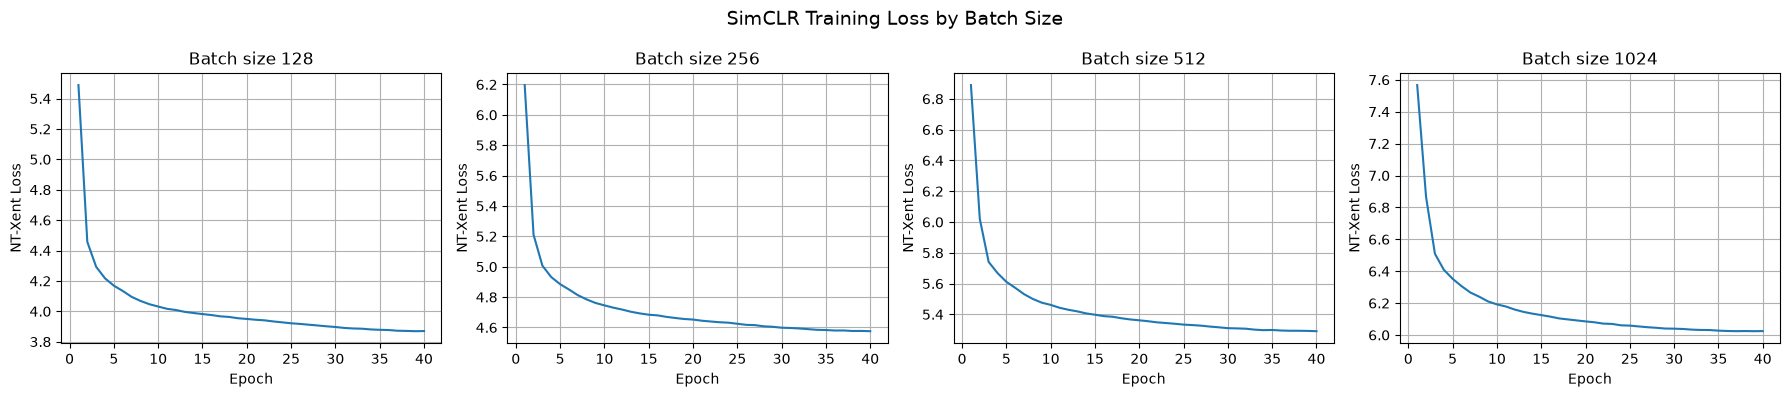

In [24]:
# Plot SimCLR training loss for each batch size (`res` from the batch-size experiment)
batch_sizes_run = list(res)
fig, axes = plt.subplots(1, len(batch_sizes_run), figsize=(4.5 * len(batch_sizes_run), 4), squeeze=False)

for ax, bs in zip(axes[0], batch_sizes_run):
    losses = res[bs]['history']['loss']
    ax.plot(range(1, len(losses) + 1), losses)
    ax.set_xlabel('Epoch')
    ax.set_ylabel('NT-Xent Loss')
    ax.set_title(f'Batch size {bs}')
    ax.grid(True)

plt.suptitle('SimCLR Training Loss by Batch Size', fontsize=14)
plt.tight_layout()
plt.show()


In [25]:
# Plot the batch-size experiment (`res` from the experiment cell) in W&B:
# one loss-vs-epoch chart per batch size, all batch sizes on one chart,
# and best test accuracy vs. batch size.
finish_stale_wandb_run()

batch_sizes_run = list(res)
n_epochs = len(res[batch_sizes_run[0]]['history']['loss'])
epochs_axis = list(range(1, n_epochs + 1))

run = wandb.init(
    project='simclr-batch-size',
    name='batch-size-comparison-curves',
    config={'batch_sizes': batch_sizes_run, 'simclr_epochs': n_epochs},
)

# One loss curve per batch size
for bs in batch_sizes_run:
    loss_table = wandb.Table(
        columns=['epoch', 'loss'],
        data=[[e, l] for e, l in zip(epochs_axis, res[bs]['history']['loss'])],
    )
    wandb.log({
        f'loss_curve_bs{bs}': wandb.plot.line(
            loss_table, 'epoch', 'loss',
            title=f'SimCLR training loss (batch size {bs})',
        ),
    })

# All loss curves on a single chart
wandb.log({
    'loss_vs_epoch': wandb.plot.line_series(
        xs=epochs_axis,
        ys=[res[bs]['history']['loss'] for bs in batch_sizes_run],
        keys=[f'batch size {bs}' for bs in batch_sizes_run],
        title='SimCLR training loss by batch size',
        xname='epoch',
    ),
})

# Best linear-probe accuracy per batch size
acc_table = wandb.Table(
    columns=['batch_size', 'best_test_acc (%)'],
    data=[[str(bs), res[bs]['best_test_acc'] * 100] for bs in batch_sizes_run],
)
wandb.log({
    'best_test_acc_vs_batch_size': wandb.plot.bar(
        acc_table, 'batch_size', 'best_test_acc (%)',
        title='Best linear-probe test accuracy by batch size',
    ),
})
for bs in batch_sizes_run:
    run.summary[f'best_test_acc_bs{bs}'] = res[bs]['best_test_acc']

wandb.finish()


wandb: [wandb.login()] Loaded credentials for https://api.forge.coreweave.com from /home/lone-warrior/.netrc.
wandb: Currently logged in as: roopanshabugada (roopanshabugada-iit-hyderabad) to https://api.forge.coreweave.com. Use `wandb login --relogin` to force relogin


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


best_test_acc_bs1024,0.6773
best_test_acc_bs128,0.774
best_test_acc_bs256,0.7609
best_test_acc_bs512,0.7162


In [23]:
# Rebuild `res` from the saved W&B summary of the 40-epoch batch-size run (no retraining)
import json
import wandb

summary_path = 'wandb/run-20261029_012321-ll1rw0m7/files/wandb-summary.json'
summary = json.load(open(summary_path))
res = {
    bs: {
        'history': {'loss': summary[f'batch_size_{bs}/loss']},
        'best_test_acc': summary[f'batch_size_{bs}/best_test_acc'],
    }
    for bs in [128, 256, 512, 1024]
}

def finish_stale_wandb_run():
    """Needed by the W&B cell; normally defined in the batch-size experiment cell."""
    if wandb.run is not None:
        wandb.finish()

for bs, r in res.items():
    print(f'batch size {bs:4d}: {len(r["history"]["loss"])} epochs, '
          f'final loss {r["history"]["loss"][-1]:.4f}, best test acc {r["best_test_acc"]*100:.2f}%')


batch size  128: 40 epochs, final loss 3.8701, best test acc 77.40%
batch size  256: 40 epochs, final loss 4.5754, best test acc 76.09%
batch size  512: 40 epochs, final loss 5.2909, best test acc 71.62%
batch size 1024: 40 epochs, final loss 6.0246, best test acc 67.73%


## Augmentation Experiments (following SimCLR §3)

- **A — Composition:** random crop, color distortion, cutout and rotation, applied individually and in pairs (paper Figure 5). Horizontal flip is always on.
- **B — Color distortion strength:** crop + color with s ∈ {0, 0.25, 0.5, 1.0} (paper Table 1). s = 0.5 is the crop + color run from A, so it is reused. With s = 0 the color jitter is off but random grayscale still applies.
- **D — Why color matters:** pixel-intensity histograms of random crops of the same image, without and with color distortion (paper Figure 6).

Every run uses the paper's training recipe for batch size 256: LARS with LR = 0.3 × 256/256 = 0.3, momentum 0.9, weight decay 1e-6 (biases and BatchNorm excluded), linear warmup over the first 10% of steps followed by cosine decay, temperature 0.5. Color distortion follows the paper's definition: jitter (0.8s, 0.8s, 0.8s, 0.2s) with probability 0.8, then grayscale with probability 0.2. All runs start from the same initialisation and are evaluated with the same linear probe on frozen features.

Each configuration is logged as its own W&B run (loss, contrastive accuracy and learning rate at every step and every epoch). Its weights and results are saved under `checkpoints/augmentations/`, and finished configurations are skipped when a cell is re-run, so an interrupted experiment continues where it stopped.

In [26]:
import os, json, math, time
from itertools import combinations
import wandb

# ---- Settings shared by every augmentation run (SimCLR recipe for batch size 256) ----
AUG_EPOCHS = 20
AUG_BATCH_SIZE = 256
AUG_BASE_LR = 0.3 * AUG_BATCH_SIZE / 256   # SimCLR: LR = 0.3 × BatchSize / 256, with LARS
AUG_WEIGHT_DECAY = 1e-6
AUG_TEMPERATURE = 0.5
AUG_WARMUP_FRACTION = 0.1                  # paper: 10 warmup epochs out of 100
AUG_CROP_SCALE = (0.08, 1.0)               # paper's random crop area range
AUG_COLOR_S = 0.5                          # paper's color distortion strength for CIFAR-10
AUG_B_STRENGTHS = [0.0, 0.25, 0.5, 1.0]    # experiment B
AUG_NAMES = ['crop', 'color', 'cutout', 'rotate']
AUG_LINEAR_EVAL_EPOCHS = 100
AUG_SEED = 0                               # same initialisation and data order for every run
AUG_WANDB_PROJECT = 'simclr-augmentations'
AUG_CKPT_DIR = 'checkpoints/augmentations'
AUG_FIG_DIR = 'results/augmentations'
AUG_RESULTS_PATH = os.path.join(AUG_CKPT_DIR, 'results.json')
os.makedirs(AUG_CKPT_DIR, exist_ok=True)
os.makedirs(AUG_FIG_DIR, exist_ok=True)


class RandomRotate90(nn.Module):
    """Rotate every image by a random 90°, 180° or 270° (the paper's rotation)."""
    def forward(self, x):
        k = torch.randint(1, 4, (x.shape[0],), device=x.device)
        out = x.clone()
        for r in (1, 2, 3):
            mask = k == r
            if mask.any():
                out[mask] = torch.rot90(x[mask], r, dims=(2, 3))
        return out


def build_aug_pipeline(augs, s=AUG_COLOR_S):
    """Horizontal flip + the chosen augmentations + normalization, run on the GPU.

    `augs` is any subset of AUG_NAMES. Kornia samples random parameters per image.
    """
    ops = []
    if 'crop' in augs:
        ops.append(K.RandomResizedCrop((32, 32), scale=AUG_CROP_SCALE))
    ops.append(K.RandomHorizontalFlip())
    if 'rotate' in augs:
        ops.append(RandomRotate90())
    if 'color' in augs:
        if s > 0:
            ops.append(K.ColorJitter(0.8*s, 0.8*s, 0.8*s, 0.2*s, p=0.8))
        ops.append(K.RandomGrayscale(p=0.2))
    if 'cutout' in augs:
        ops.append(K.RandomErasing(scale=(0.02, 0.25), ratio=(1.0, 1.0), value=0.0, p=1.0))  # square, up to half the side
    ops.append(K.Normalize(torch.tensor(CIFAR10_MEAN), torch.tensor(CIFAR10_STD)))
    return nn.Sequential(*ops).to(device)


class LARS(optim.Optimizer):
    """LARS (You et al., 2017) as used by SimCLR: SGD with momentum where each weight
    tensor's update is scaled by eta * ||w|| / ||g||. Parameter groups with lars=False
    (biases and BatchNorm) get a plain momentum update without weight decay."""
    def __init__(self, params, lr, momentum=0.9, weight_decay=0.0, eta=0.001):
        super().__init__(params, dict(lr=lr, momentum=momentum, weight_decay=weight_decay,
                                      eta=eta, lars=True))

    @torch.no_grad()
    def step(self, closure=None):
        for group in self.param_groups:
            for p in group['params']:
                if p.grad is None:
                    continue
                d_p = p.grad
                if group['lars']:
                    d_p = d_p.add(p, alpha=group['weight_decay'])
                    w_norm, g_norm = torch.norm(p), torch.norm(d_p)
                    trust = torch.where((w_norm > 0) & (g_norm > 0),
                                        group['eta'] * w_norm / g_norm, torch.ones_like(w_norm))
                    d_p = d_p.mul(trust)
                state = self.state[p]
                if 'momentum_buffer' not in state:
                    state['momentum_buffer'] = d_p.clone()
                else:
                    state['momentum_buffer'].mul_(group['momentum']).add_(d_p)
                p.add_(state['momentum_buffer'], alpha=-group['lr'])


def lars_param_groups(model, weight_decay):
    """Weights get LARS + weight decay; biases and BatchNorm parameters get neither."""
    weights = [p for p in model.parameters() if p.ndim > 1]
    others = [p for p in model.parameters() if p.ndim <= 1]
    return [dict(params=weights, weight_decay=weight_decay, lars=True),
            dict(params=others, weight_decay=0.0, lars=False)]


@torch.no_grad()
def contrastive_accuracy(z1, z2):
    """Fraction of the 2N views whose most similar other view is their positive pair."""
    z = F.normalize(torch.cat([z1, z2]), dim=1)
    sim = z @ z.t()
    sim.fill_diagonal_(-float('inf'))
    n = z1.shape[0]
    target = torch.cat([torch.arange(n, 2 * n), torch.arange(0, n)]).to(z.device)
    return (sim.argmax(dim=1) == target).float().mean()


def train_simclr_lars(model, loader, epochs, run=None):
    """SimCLR pre-training with the paper's recipe. Logs every step and every epoch to `run`."""
    model.train()
    optimizer = LARS(lars_param_groups(model, AUG_WEIGHT_DECAY), lr=AUG_BASE_LR)
    criterion = NTXentLoss(temperature=AUG_TEMPERATURE)
    steps_per_epoch = len(loader)
    total_steps = epochs * steps_per_epoch
    warmup_steps = max(1, round(AUG_WARMUP_FRACTION * total_steps))

    def lr_at(step):
        if step < warmup_steps:
            return AUG_BASE_LR * (step + 1) / warmup_steps
        progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return AUG_BASE_LR * 0.5 * (1 + math.cos(math.pi * progress))

    history = {'loss': [], 'contrastive_acc': [], 'lr': []}
    step = 0
    for epoch in tqdm(range(epochs), desc='Epochs', leave=False):
        epoch_loss = epoch_acc = 0.0
        batch_iterator = tqdm(loader, desc=f'Epoch {epoch + 1}/{epochs}', leave=False)
        for view1, view2 in batch_iterator:
            lr = lr_at(step)
            for group in optimizer.param_groups:
                group['lr'] = lr

            _, z1 = model(view1)
            _, z2 = model(view2)
            loss = criterion(z1, z2)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()

            loss_val = loss.item()
            acc_val = contrastive_accuracy(z1.detach(), z2.detach()).item()
            epoch_loss += loss_val
            epoch_acc += acc_val
            step += 1
            batch_iterator.set_postfix(loss=f'{loss_val:.4f}')
            if run is not None:
                run.log({'global_step': step, 'train/loss': loss_val, 'train/contrastive_acc': acc_val,
                         'train/lr': lr, 'train/epoch': step / steps_per_epoch})

        history['loss'].append(epoch_loss / steps_per_epoch)
        history['contrastive_acc'].append(epoch_acc / steps_per_epoch)
        history['lr'].append(lr)
        if run is not None:
            run.log({'epoch': epoch + 1, 'epoch/loss': history['loss'][-1],
                     'epoch/contrastive_acc': history['contrastive_acc'][-1], 'epoch/lr': lr})
        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f'  Epoch [{epoch + 1}/{epochs}]  Loss: {history["loss"][-1]:.4f}  '
                  f'Contrastive acc: {history["contrastive_acc"][-1]:.3f}  LR: {lr:.4f}')
    return history


def close_wandb_run():
    """Finish any open W&B run; recover if an interrupt killed wandb's background process."""
    if wandb.run is not None:
        try:
            wandb.finish()
        except Exception:
            try:
                wandb.teardown()
            except Exception:
                pass
    wandb.login()


def load_aug_results():
    if os.path.exists(AUG_RESULTS_PATH):
        with open(AUG_RESULTS_PATH) as f:
            return json.load(f)
    return {}


def save_aug_result(name, result):
    results = load_aug_results()
    results[name] = result
    tmp_path = AUG_RESULTS_PATH + '.tmp'
    with open(tmp_path, 'w') as f:
        json.dump(results, f, indent=1)
    os.replace(tmp_path, AUG_RESULTS_PATH)   # never leaves a half-written results file


def run_aug_config(name, augs, s=AUG_COLOR_S, experiment='A'):
    """Pre-train SimCLR with one augmentation configuration, run the linear probe,
    save the weights and results, and log everything to W&B. Skips finished configs."""
    ckpt_path = os.path.join(AUG_CKPT_DIR, f'{name}.pt')
    done = load_aug_results()
    if name in done and os.path.exists(ckpt_path):
        print(f'{name}: already done (best test acc {done[name]["best_test_acc"] * 100:.2f}%), skipping')
        return done[name]

    config = dict(name=name, experiment=experiment, augmentations=[a for a in AUG_NAMES if a in augs],
                  color_strength=s if 'color' in augs else None, epochs=AUG_EPOCHS,
                  batch_size=AUG_BATCH_SIZE, optimizer='LARS', lr=AUG_BASE_LR,
                  weight_decay=AUG_WEIGHT_DECAY, temperature=AUG_TEMPERATURE,
                  warmup_fraction=AUG_WARMUP_FRACTION, crop_scale=list(AUG_CROP_SCALE),
                  linear_eval_epochs=AUG_LINEAR_EVAL_EPOCHS, seed=AUG_SEED)
    print(f'\n{"=" * 60}\n{name}: {" + ".join(config["augmentations"])} (+ flip)'
          + (f', s = {s}' if 'color' in augs else '') + f'\n{"=" * 60}')

    close_wandb_run()
    run = wandb.init(project=AUG_WANDB_PROJECT, group=f'experiment-{experiment}', name=name, config=config)
    run.define_metric('global_step')
    run.define_metric('train/*', step_metric='global_step')
    run.define_metric('epoch')
    run.define_metric('epoch/*', step_metric='epoch')
    try:
        torch.manual_seed(AUG_SEED)
        model = SimCLRModel(feature_dim=512, projection_dim=128).to(device)
        loader = GPULoader(train_x, None, batch_size=AUG_BATCH_SIZE, shuffle=True, drop_last=True,
                           transform=SimCLRAugmentation(build_aug_pipeline(augs, s)))
        start = time.time()
        history = train_simclr_lars(model, loader, AUG_EPOCHS, run)
        train_minutes = (time.time() - start) / 60

        model.eval()
        _, best_acc, final_acc = train_linear_classifier(
            model.encoder, train_loader, test_loader, feature_dim=512, num_classes=10,
            epochs=AUG_LINEAR_EVAL_EPOCHS, lr=0.3, return_final_accuracy=True,
        )
        result = dict(config, history=history, best_test_acc=best_acc,
                      final_test_acc=final_acc, train_minutes=train_minutes)
        torch.save({'config': config, 'model_state_dict': model.state_dict(), 'history': history,
                    'best_test_acc': best_acc, 'final_test_acc': final_acc}, ckpt_path)
        save_aug_result(name, result)
        run.summary.update({'best_test_acc': best_acc, 'final_test_acc': final_acc,
                            'train_minutes': train_minutes})
        print(f'{name}: best test acc {best_acc * 100:.2f}%  ({train_minutes:.1f} min), '
              f'weights saved to {ckpt_path}')
    finally:
        try:
            run.finish()
        except Exception:
            pass   # wandb was stopped by an interrupt; close_wandb_run() recovers next time
    return result


In [27]:
# Experiment A — every augmentation alone and in pairs (SimCLR Figure 5)
aug_combos_A = [(a,) for a in AUG_NAMES] + list(combinations(AUG_NAMES, 2))
print(f'{len(aug_combos_A)} configurations: {["+".join(c) for c in aug_combos_A]}')

for augs in aug_combos_A:
    run_aug_config('A_' + '+'.join(augs), augs, experiment='A')


10 configurations: ['crop', 'color', 'cutout', 'rotate', 'crop+color', 'crop+cutout', 'crop+rotate', 'color+cutout', 'color+rotate', 'cutout+rotate']

A_crop: crop (+ flip)


Feature dimension (before FC): 512


Epochs:   0%|          | 0/20 [00:00<?, ?it/s]

Epoch 1/20:   0%|          | 0/195 [00:00<?, ?it/s]

  Epoch [1/20]  Loss: 5.2328  Contrastive acc: 0.305  LR: 0.1500


...

Extracting features:   0%|          | 0/40 [00:00<?, ?it/s]

Epoch [1/100]  Test Accuracy: 0.2326 (23.26%)
Epoch [10/100]  Test Accuracy: 0.2532 (25.32%)
Epoch [20/100]  Test Accuracy: 0.2656 (26.56%)
Epoch [30/100]  Test Accuracy: 0.2622 (26.22%)
Epoch [40/100]  Test Accuracy: 0.3110 (31.10%)
Epoch [50/100]  Test Accuracy: 0.3041 (30.41%)
Epoch [60/100]  Test Accuracy: 0.2761 (27.61%)
Epoch [70/100]  Test Accuracy: 0.2809 (28.09%)
Epoch [80/100]  Test Accuracy: 0.3149 (31.49%)
Epoch [90/100]  Test Accuracy: 0.3098 (30.98%)


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


Epoch [100/100]  Test Accuracy: 0.2765 (27.65%)

Final Test Accuracy: 0.2765 (27.65%)
Best Test Accuracy: 0.3495 (34.95%)
A_cutout+rotate: best test acc 34.95%  (10.1 min), weights saved to checkpoints/augmentations/A_cutout+rotate.pt


epoch,▁▁▂▂▂▃▃▄▄▄▅▅▅▆▆▇▇▇██
epoch/contrastive_acc,▁▇██████████████████
epoch/loss,█▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
epoch/lr,▄████▇▇▆▆▅▅▄▃▃▂▂▁▁▁▁
global_step,▁▁▁▁▂▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▅▅▅▅▅▅▅▆▆▆▇▇▇▇▇█████
train/contrastive_acc,▁▅██████████████████████████████████████
train/epoch,▁▁▁▁▂▂▂▂▃▃▃▃▄▄▄▄▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▆▆▆▇▇████
train/loss,█▆▄▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/lr,▁▂▃▃▆█████████▇▇▇▇▇▇▆▆▅▄▄▄▃▃▂▂▂▂▂▂▂▂▁▁▁▁
best_test_acc,0.3495
epoch,20


In [28]:
# Experiment B — color distortion strength with crop + color (SimCLR Table 1)
for s in AUG_B_STRENGTHS:
    if s == AUG_COLOR_S:
        print(f's = {s}: same configuration as A_crop+color, reusing that run')
        continue
    run_aug_config(f'B_crop+color_s{s}', ('crop', 'color'), s=s, experiment='B')



B_crop+color_s0.0: crop + color (+ flip), s = 0.0


Feature dimension (before FC): 512


Epochs:   0%|          | 0/20 [00:00<?, ?it/s]

Epoch 1/20:   0%|          | 0/195 [00:00<?, ?it/s]

  Epoch [1/20]  Loss: 5.4339  Contrastive acc: 0.196  LR: 0.1500


...

Extracting features:   0%|          | 0/40 [00:00<?, ?it/s]

Epoch [1/100]  Test Accuracy: 0.4713 (47.13%)
Epoch [10/100]  Test Accuracy: 0.5406 (54.06%)
Epoch [20/100]  Test Accuracy: 0.5192 (51.92%)
Epoch [30/100]  Test Accuracy: 0.5606 (56.06%)
Epoch [40/100]  Test Accuracy: 0.4971 (49.71%)
Epoch [50/100]  Test Accuracy: 0.5429 (54.29%)
Epoch [60/100]  Test Accuracy: 0.5198 (51.98%)
Epoch [70/100]  Test Accuracy: 0.5068 (50.68%)
Epoch [80/100]  Test Accuracy: 0.5717 (57.17%)
Epoch [90/100]  Test Accuracy: 0.5267 (52.67%)


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


Epoch [100/100]  Test Accuracy: 0.5352 (53.52%)

Final Test Accuracy: 0.5352 (53.52%)
Best Test Accuracy: 0.5925 (59.25%)
B_crop+color_s1.0: best test acc 59.25%  (13.8 min), weights saved to checkpoints/augmentations/B_crop+color_s1.0.pt


epoch,▁▁▂▂▂▃▃▄▄▄▅▅▅▆▆▇▇▇██
epoch/contrastive_acc,▁▂▂▃▄▅▅▆▆▆▇▇▇▇██████
epoch/loss,█▆▄▄▃▃▂▂▂▂▂▁▁▁▁▁▁▁▁▁
epoch/lr,▄████▇▇▆▆▅▅▄▃▃▂▂▁▁▁▁
global_step,▁▁▁▁▂▂▂▂▃▃▃▃▃▃▃▄▄▄▄▅▅▅▅▅▅▆▆▆▇▇▇▇▇▇▇█████
train/contrastive_acc,▁▂▁▂▂▃▃▄▄▃▅▅▅▅▄▅▅▅▅▆▆▆▆▆▇▆▇▇▇▇▇▇▇██▆█▇▆▇
train/epoch,▁▁▁▁▁▂▂▂▂▃▃▃▄▄▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▆▆▆▆▇▇█████
train/loss,███▆▆▅▅▅▄▃▃▃▃▃▂▂▂▂▂▂▂▂▁▂▂▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁
train/lr,▄▄▆████████▇▇▇▆▆▆▆▆▆▆▆▅▅▅▄▃▃▃▃▂▂▂▂▂▂▁▁▁▁
best_test_acc,0.5925
epoch,20


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


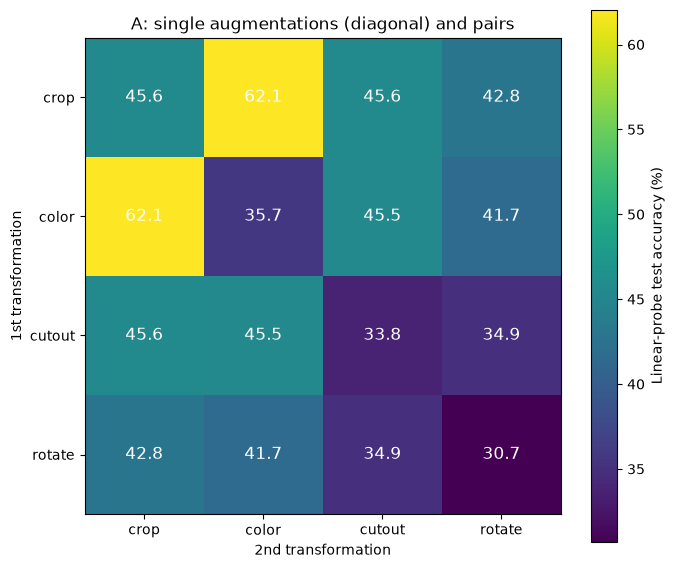

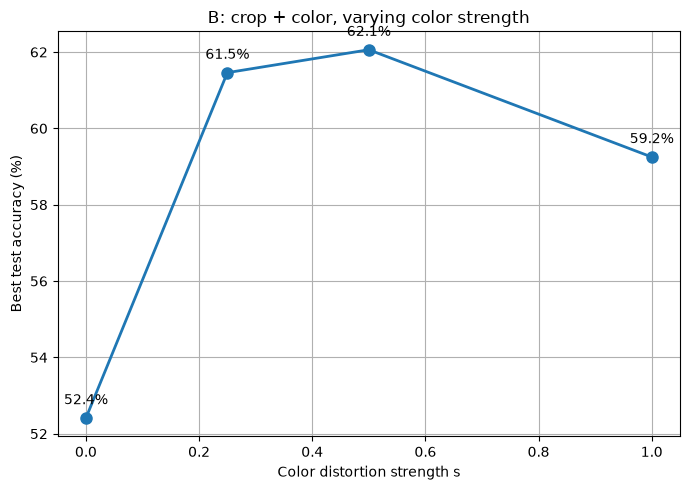

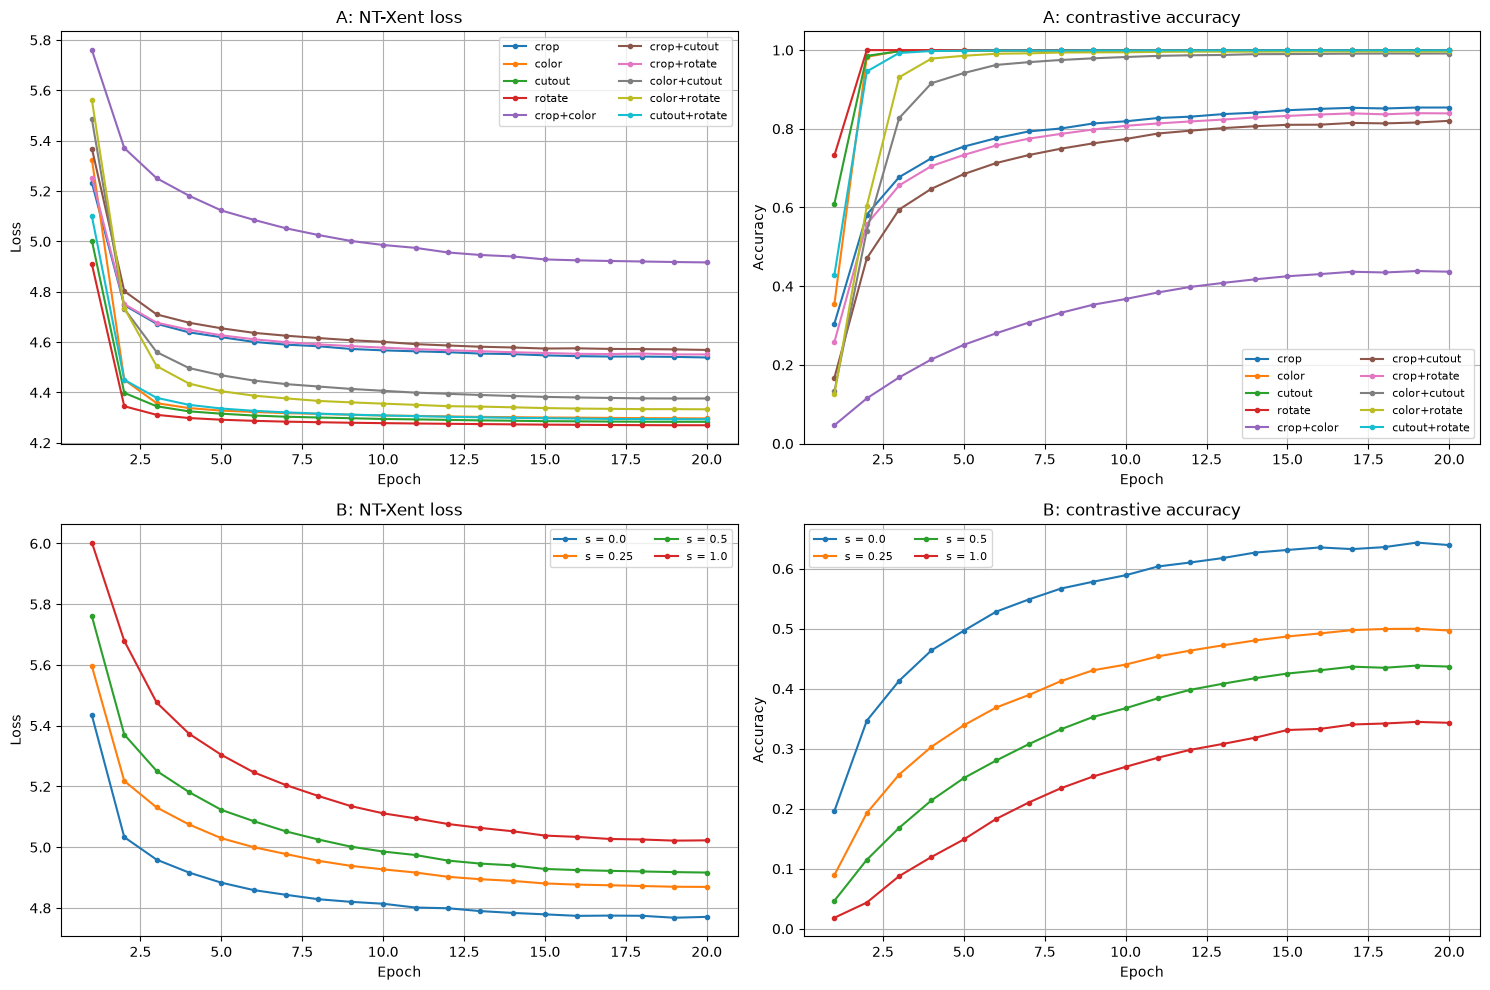

13 finished runs; figures saved in results/augmentations/


In [29]:
# Results of experiments A and B: plots here, saved as PNGs, and logged to a W&B summary run
aug_results = load_aug_results()

def aug_result(augs, s=AUG_COLOR_S):
    """Finished run for a set of augmentations (B's s = 0.5 run is A's crop+color)."""
    if 'color' in augs and s != AUG_COLOR_S:
        return aug_results.get(f'B_crop+color_s{s}')
    return aug_results.get('A_' + '+'.join(a for a in AUG_NAMES if a in augs))

# --- A: accuracy heatmap (diagonal = single augmentation, off-diagonal = pair)
n_augs = len(AUG_NAMES)
acc_matrix = np.full((n_augs, n_augs), np.nan)
for i, a in enumerate(AUG_NAMES):
    for j, b in enumerate(AUG_NAMES):
        r = aug_result({a, b})
        if r is not None:
            acc_matrix[i, j] = r['best_test_acc'] * 100

fig_a, ax = plt.subplots(figsize=(7, 6))
heat_cmap = plt.get_cmap('viridis').copy()
heat_cmap.set_bad('lightgray')   # configurations without a result yet
im = ax.imshow(np.ma.masked_invalid(acc_matrix), cmap=heat_cmap)
ax.set_xticks(range(n_augs)); ax.set_xticklabels(AUG_NAMES)
ax.set_yticks(range(n_augs)); ax.set_yticklabels(AUG_NAMES)
ax.set_xlabel('2nd transformation'); ax.set_ylabel('1st transformation')
for i in range(n_augs):
    for j in range(n_augs):
        missing = np.isnan(acc_matrix[i, j])
        ax.text(j, i, '—' if missing else f'{acc_matrix[i, j]:.1f}', ha='center', va='center',
                color='dimgray' if missing else 'white', fontsize=12)
fig_a.colorbar(im, ax=ax, label='Linear-probe test accuracy (%)')
ax.set_title('A: single augmentations (diagonal) and pairs')
fig_a.tight_layout()

# --- B: accuracy vs color strength
b_points = [(s, aug_result({'crop', 'color'}, s)) for s in AUG_B_STRENGTHS]
b_points = [(s, r['best_test_acc'] * 100) for s, r in b_points if r is not None]
fig_b, ax = plt.subplots(figsize=(7, 5))
if b_points:
    ax.plot([s for s, _ in b_points], [acc for _, acc in b_points], 'o-', linewidth=2, markersize=8)
    for s, acc in b_points:
        ax.annotate(f'{acc:.1f}%', (s, acc), textcoords='offset points', xytext=(0, 10), ha='center')
ax.set_xlabel('Color distortion strength s'); ax.set_ylabel('Best test accuracy (%)')
ax.set_title('B: crop + color, varying color strength'); ax.grid(True)
fig_b.tight_layout()

# --- Training curves for every run: loss and contrastive accuracy per epoch
a_runs = {k: v for k, v in aug_results.items() if v['experiment'] == 'A'}
b_runs = {f's = {s}': aug_result({'crop', 'color'}, s) for s in AUG_B_STRENGTHS}
b_runs = {k: v for k, v in b_runs.items() if v is not None}
fig_curves, axes = plt.subplots(2, 2, figsize=(15, 10))
for row, (title, runs) in enumerate([('A', a_runs), ('B', b_runs)]):
    for label, r in runs.items():
        epochs_axis = range(1, len(r['history']['loss']) + 1)
        label = label.removeprefix('A_')
        axes[row, 0].plot(epochs_axis, r['history']['loss'], marker='.', label=label)
        axes[row, 1].plot(epochs_axis, r['history']['contrastive_acc'], marker='.', label=label)
    axes[row, 0].set_title(f'{title}: NT-Xent loss'); axes[row, 0].set_ylabel('Loss')
    axes[row, 1].set_title(f'{title}: contrastive accuracy'); axes[row, 1].set_ylabel('Accuracy')
    for ax in axes[row]:
        ax.set_xlabel('Epoch'); ax.grid(True); ax.legend(fontsize=8, ncol=2)
fig_curves.tight_layout()

for fig, fname in [(fig_a, 'A_heatmap.png'), (fig_b, 'B_color_strength.png'), (fig_curves, 'training_curves.png')]:
    fig.savefig(os.path.join(AUG_FIG_DIR, fname), dpi=120)

# --- W&B summary run: result table, interactive charts and the figures above
close_wandb_run()
summary_run = wandb.init(project=AUG_WANDB_PROJECT, group='summary', name='augmentation-summary',
                         config={'epochs': AUG_EPOCHS, 'batch_size': AUG_BATCH_SIZE, 'lr': AUG_BASE_LR})
results_table = wandb.Table(
    columns=['name', 'experiment', 'augmentations', 'color_strength', 'best_test_acc (%)', 'final_test_acc (%)'],
    data=[[k, v['experiment'], ' + '.join(v['augmentations']), v['color_strength'],
           v['best_test_acc'] * 100, v['final_test_acc'] * 100] for k, v in aug_results.items()],
)
charts = {'results_table': results_table, 'A_heatmap': wandb.Image(fig_a),
          'B_color_strength_figure': wandb.Image(fig_b), 'training_curves': wandb.Image(fig_curves)}
if a_runs:
    a_table = wandb.Table(columns=['configuration', 'best_test_acc (%)'],
                          data=[[k.removeprefix('A_'), v['best_test_acc'] * 100] for k, v in a_runs.items()])
    charts['A_accuracy'] = wandb.plot.bar(a_table, 'configuration', 'best_test_acc (%)',
                                          title='A: best linear-probe accuracy per configuration')
    charts['A_loss_vs_epoch'] = wandb.plot.line_series(
        xs=list(range(1, AUG_EPOCHS + 1)), ys=[v['history']['loss'] for v in a_runs.values()],
        keys=[k.removeprefix('A_') for k in a_runs], title='A: NT-Xent loss', xname='epoch')
if b_runs:
    b_table = wandb.Table(columns=['color_strength', 'best_test_acc (%)'], data=[[s, acc] for s, acc in b_points])
    charts['B_accuracy_vs_strength'] = wandb.plot.line(b_table, 'color_strength', 'best_test_acc (%)',
                                                       title='B: accuracy vs color strength')
    charts['B_loss_vs_epoch'] = wandb.plot.line_series(
        xs=list(range(1, AUG_EPOCHS + 1)), ys=[v['history']['loss'] for v in b_runs.values()],
        keys=list(b_runs), title='B: NT-Xent loss', xname='epoch')
summary_run.log(charts)
summary_run.finish()

plt.show()
print(f'{len(aug_results)} finished runs; figures saved in {AUG_FIG_DIR}/')


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


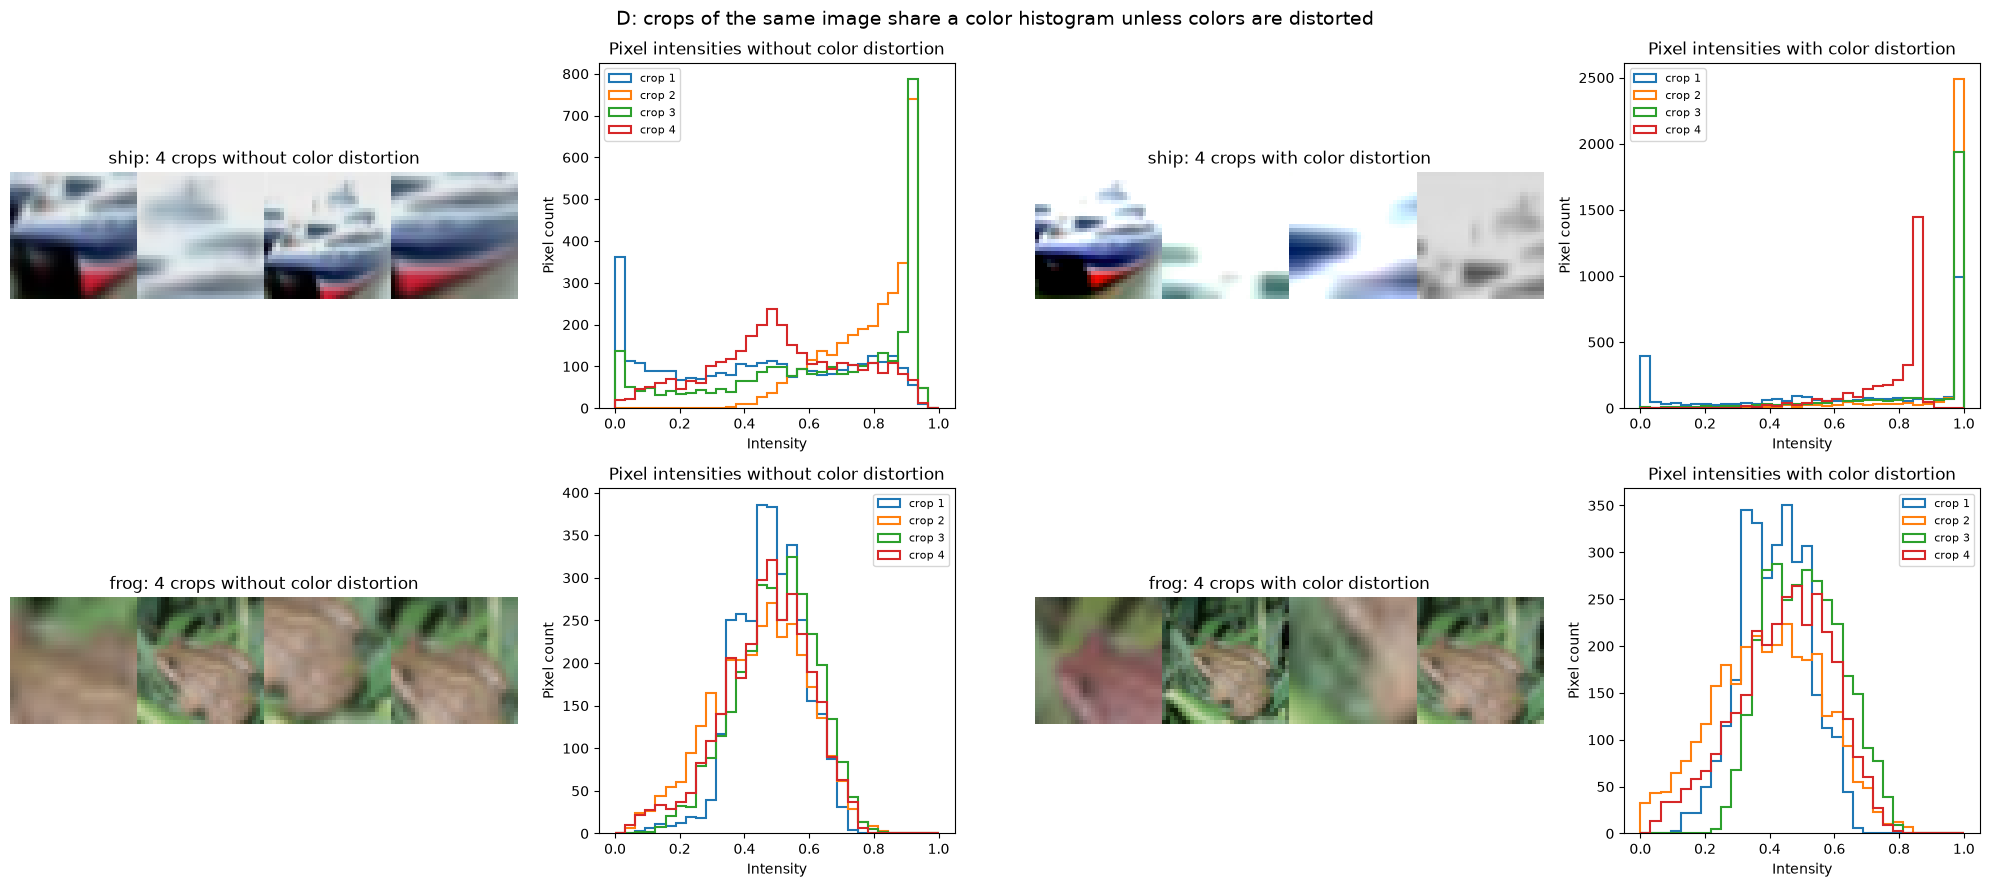

In [30]:
# Experiment D — why color distortion matters (SimCLR Figure 6): pixel-intensity histograms
# of random crops of the same image, without and with color distortion
s = AUG_COLOR_S
crop_only = nn.Sequential(K.RandomResizedCrop((32, 32), scale=AUG_CROP_SCALE)).to(device)
crop_color = nn.Sequential(
    K.RandomResizedCrop((32, 32), scale=AUG_CROP_SCALE),
    K.ColorJitter(0.8*s, 0.8*s, 0.8*s, 0.2*s, p=0.8),
    K.RandomGrayscale(p=0.2),
).to(device)

N_CROPS = 4
image_ids = [int((test_y == label_names.index(c)).nonzero()[0]) for c in ('ship', 'frog')]
fig_d, axes = plt.subplots(len(image_ids), 4, figsize=(20, 4.5 * len(image_ids)),
                           gridspec_kw={'width_ratios': [2, 1.4, 2, 1.4]})
torch.manual_seed(AUG_SEED)
with torch.no_grad():
    for row, idx in enumerate(image_ids):
        img = test_x[idx:idx + 1].float().div(255).repeat(N_CROPS, 1, 1, 1)
        for col, (title, pipeline) in enumerate([('without color distortion', crop_only),
                                                 ('with color distortion', crop_color)]):
            crops = pipeline(img).clamp(0, 1).cpu()
            ax_img, ax_hist = axes[row, 2 * col], axes[row, 2 * col + 1]
            ax_img.imshow(torch.cat(list(crops), dim=2).permute(1, 2, 0).numpy())  # crops side by side
            ax_img.set_title(f'{label_names[test_y[idx]]}: {N_CROPS} crops {title}')
            ax_img.axis('off')
            for k, crop in enumerate(crops):
                ax_hist.hist(crop.flatten().numpy(), bins=32, range=(0, 1), histtype='step',
                             linewidth=1.5, label=f'crop {k + 1}')
            ax_hist.set_title(f'Pixel intensities {title}')
            ax_hist.set_xlabel('Intensity'); ax_hist.set_ylabel('Pixel count')
            ax_hist.legend(fontsize=8)
fig_d.suptitle('D: crops of the same image share a color histogram unless colors are distorted', fontsize=14)
fig_d.tight_layout()
fig_d.savefig(os.path.join(AUG_FIG_DIR, 'D_color_histograms.png'), dpi=120)

close_wandb_run()
d_run = wandb.init(project=AUG_WANDB_PROJECT, group='experiment-D', name='D_color_histograms',
                   config={'color_strength': s, 'crop_scale': list(AUG_CROP_SCALE)})
d_run.log({'D_color_histograms': wandb.Image(fig_d)})
d_run.finish()
plt.show()


## 6. DeepCluster — Self-Supervised Learning by Clustering

DeepCluster (Caron et al., 2018) alternates between clustering the network's features and training the network to predict those clusters. Every epoch:

1. **Features:** the current encoder computes the features of all 50k training images (no augmentation).
2. **Clustering:** the features are PCA-whitened to 256 dimensions, L2-normalized, and grouped with k-means into k = 100 clusters. That is 10× the number of classes, mirroring the paper's 10 000 clusters for ImageNet's 1000 classes.
3. **Pseudo-labels:** each image's cluster becomes its label. The linear "top layer" that predicts the cluster is re-initialized, because cluster ids mean something different after every clustering.
4. **Training:** encoder and top layer are trained with cross-entropy on the pseudo-labels for one epoch. Images are sampled uniformly over the clusters, so one huge cluster can't take over (the trivial solution the paper warns about).

**Kept the same as SimCLR, so the two methods are comparable:**
- **Backbone:** the same CIFAR ResNet-18 encoder (`get_resnet18_cifar`, 512-d features), evaluated with the same 100-epoch linear probe on frozen features.
- **Augmentations:** the same GPU pipeline as SimCLR's training (`build_gpu_transform(s=0.5)`: random resized crop, flip, color jitter, grayscale), one augmented view per image. The paper's Sobel filter is left out: it would change the backbone's input layer, and color jitter + grayscale already stop the clusters from forming around color.
- **Batch sizes:** 128, 256, 512 and 1024, as in the SimCLR batch-size experiment, each trained for `DC_EPOCHS` epochs.

**Optimizer (DeepCluster paper):** SGD with momentum 0.9 and weight decay 1e-5, LR 0.05 at batch size 256, scaled linearly with batch size (0.025 / 0.05 / 0.1 / 0.2) and constant during training.

Besides the loss, each run tracks the paper's two diagnostics: **NMI between the clusters and the true labels** (how semantic the clusters are; labels are never used for training) and **NMI between consecutive epochs' clusterings** (how stable they are). Every run logs per step and per epoch to the W&B project `deepcluster-batch-size`. Its weights, final cluster assignments and history are saved under `checkpoints/deepcluster/`. Re-running the experiment cell skips batch sizes already trained for `DC_EPOCHS` epochs. A batch size saved with fewer epochs continues training from its saved weights (so raising `DC_EPOCHS` from 15 to 30 trains 15 more epochs), and its shorter run is kept in `checkpoints/deepcluster_<N>epochs/`.

In [41]:
import os, json, time, shutil
import wandb
from sklearn.metrics import normalized_mutual_info_score

# ---- DeepCluster settings: paper recipe, with SimCLR's backbone, augmentations and batch sizes ----
DC_BATCH_SIZES = [128, 256, 512, 1024]   # same batch sizes as the SimCLR batch-size experiment
DC_EPOCHS = 45                           # total epochs; runs saved with fewer epochs continue from their weights
DC_NUM_CLUSTERS = 100                    # k = 10 × classes (paper: 10 000 clusters for ImageNet's 1000 classes)
DC_PCA_DIM = 256                         # paper: PCA-whiten to 256 dims and L2-normalize before k-means
DC_KMEANS_ITERS = 20                     # paper (faiss): 20 k-means iterations
DC_BASE_LR = 0.05                        # paper: SGD, LR 0.05 at batch size 256
DC_MOMENTUM = 0.9
DC_WEIGHT_DECAY = 1e-5
DC_LINEAR_EVAL_EPOCHS = 100
DC_SEED = 0                              # same initialisation for every batch size
DC_WANDB_PROJECT = 'deepcluster-batch-size'
DC_CKPT_DIR = 'checkpoints/deepcluster'
DC_FIG_DIR = 'results/deepcluster'
DC_RESULTS_PATH = os.path.join(DC_CKPT_DIR, 'results.json')
os.makedirs(DC_CKPT_DIR, exist_ok=True)
os.makedirs(DC_FIG_DIR, exist_ok=True)

# Same augmentations as SimCLR's training (default_transform in cell 25), one view per image
dc_transform = build_gpu_transform(s=0.5)


def deepcluster_lr(batch_size):
    """Paper LR for batch size 256, scaled linearly with batch size (like SimCLR's 0.3 × BatchSize / 256)."""
    return DC_BASE_LR * batch_size / 256


class DeepClusterModel(nn.Module):
    """The same ResNet-18 encoder as SimCLRModel, plus a linear top layer that predicts each
    image's k-means cluster. The top layer is re-initialised after every clustering."""
    def __init__(self, num_clusters=DC_NUM_CLUSTERS):
        super().__init__()
        backbone, feat_dim = get_resnet18_cifar()
        self.encoder = nn.Sequential(*list(backbone.children())[:-1])  # up to avgpool, as in SimCLRModel
        self.top_layer = nn.Linear(feat_dim, num_clusters)

    def reset_top_layer(self):
        nn.init.normal_(self.top_layer.weight, std=0.01)   # paper's initialisation
        nn.init.zeros_(self.top_layer.bias)

    def forward(self, x):
        return self.top_layer(self.encoder(x).flatten(1))


def pca_whiten(features, dim=DC_PCA_DIM):
    """PCA-whitening to `dim` dimensions followed by L2 normalisation (the paper's preprocessing)."""
    x = features - features.mean(dim=0)
    eigvals, eigvecs = torch.linalg.eigh((x.T @ x / (len(x) - 1)).double())   # ascending order
    eigvals, eigvecs = eigvals[-dim:], eigvecs[:, -dim:]
    eigvals = eigvals.clamp(min=1e-5 * eigvals[-1].item())   # don't blow up near-constant directions
    return F.normalize(x @ (eigvecs / eigvals.sqrt()).float(), dim=1)


@torch.no_grad()
def kmeans(x, k, iters=DC_KMEANS_ITERS):
    """k-means on the GPU, initialised from k random points. As in faiss (used by the paper), an
    empty cluster gets a slightly perturbed copy of the largest cluster's centroid, so the two
    split that cluster at the next assignment. Returns the assignments and the mean squared
    distance from each point to its centroid."""
    centroids = x[torch.randperm(len(x), device=x.device)[:k]].clone()
    perturb = torch.full((x.shape[1],), 1 / 1024, device=x.device)
    perturb[1::2] *= -1
    for _ in range(iters):
        assignments = torch.cdist(x, centroids).argmin(dim=1)
        counts = torch.bincount(assignments, minlength=k)
        centroids = torch.zeros_like(centroids).index_add_(0, assignments, x) / counts.clamp(min=1)[:, None]
        for empty in (counts == 0).nonzero().flatten().tolist():
            largest = counts.argmax().item()
            centroids[empty] = centroids[largest] * (1 + perturb)
            centroids[largest] = centroids[largest] * (1 - perturb)
            counts[empty] = counts[largest] // 2
            counts[largest] -= counts[empty]
    distances, assignments = torch.cdist(x, centroids).min(dim=1)
    return assignments, distances.pow(2).mean().item()


@torch.no_grad()
def cluster_train_features(encoder):
    """The clustering step: encoder features of all training images (eval mode, no augmentation),
    PCA-whitened, L2-normalized and clustered with k-means. Returns (assignments, k-means loss)."""
    encoder.eval()
    loader = GPULoader(train_x, None, batch_size=1024, shuffle=False, transform=base_transform)
    features = torch.cat([encoder(x).flatten(1) for x in loader])
    return kmeans(pca_whiten(features), DC_NUM_CLUSTERS)


class ClusterBalancedLoader:
    """Like GPULoader, but each epoch draws the same number of images from every non-empty cluster
    (the paper's uniform sampling over pseudo-labels; small clusters are sampled with replacement).
    Yields (augmented images, pseudo-labels), both on the GPU."""
    def __init__(self, images, pseudo_labels, batch_size, transform):
        self.images, self.pseudo_labels = images, pseudo_labels
        self.batch_size, self.transform = batch_size, transform

    def __len__(self):
        return len(self.images) // self.batch_size   # drop_last

    def __iter__(self):
        n = len(self.images)
        clusters = self.pseudo_labels.unique()
        per_cluster = n // len(clusters) + 1
        order = []
        for c in clusters:
            members = (self.pseudo_labels == c).nonzero().flatten()
            if len(members) > per_cluster:
                order.append(members[torch.randperm(len(members), device=members.device)[:per_cluster]])
            else:
                order.append(members[torch.randint(len(members), (per_cluster,), device=members.device)])
        order = torch.cat(order)
        order = order[torch.randperm(len(order), device=order.device)[:n]]
        for start in range(0, len(self) * self.batch_size, self.batch_size):
            idx = order[start:start + self.batch_size]
            with torch.no_grad():
                x = self.transform(self.images[idx].float().div_(255))
            yield x, self.pseudo_labels[idx]


def train_deepcluster(model, batch_size, epochs, run=None, start_epoch=0):
    """DeepCluster pre-training: every epoch, cluster the features of all training images, then
    train the network to predict each image's cluster. Logs every step and every epoch to `run`.
    With start_epoch > 0 it continues a saved run, numbering epochs and steps from there.
    Returns the history of the epochs trained here and the clustering of the final features."""
    lr = deepcluster_lr(batch_size)
    # The encoder's optimizer (and its momentum) persists across epochs. The top layer is new
    # every epoch and gets its own fresh SGD without momentum, as in the paper's code.
    optimizer = optim.SGD(model.encoder.parameters(), lr=lr, momentum=DC_MOMENTUM,
                          weight_decay=DC_WEIGHT_DECAY)
    criterion = nn.CrossEntropyLoss()
    true_labels = train_y.numpy()
    history = {'loss': [], 'pseudo_label_acc': [], 'nmi_labels': [], 'nmi_previous': [],
               'kmeans_loss': [], 'empty_clusters': [], 'lr': []}
    previous_clusters = None
    end_epoch = start_epoch + epochs
    steps_per_epoch = len(train_x) // batch_size
    step = start_epoch * steps_per_epoch
    for epoch in tqdm(range(start_epoch, end_epoch), desc='Epochs', leave=False):
        # 1) Cluster the current features: the clusters are this epoch's pseudo-labels
        assignments, kmeans_loss = cluster_train_features(model.encoder)
        clusters = assignments.cpu().numpy()
        history['nmi_labels'].append(normalized_mutual_info_score(true_labels, clusters))
        if previous_clusters is not None:   # nmi_previous starts at the second epoch trained here
            history['nmi_previous'].append(normalized_mutual_info_score(previous_clusters, clusters))
        previous_clusters = clusters
        history['kmeans_loss'].append(kmeans_loss)
        history['empty_clusters'].append(DC_NUM_CLUSTERS - len(np.unique(clusters)))

        # 2) New top layer, then one epoch of training on the pseudo-labels
        model.reset_top_layer()
        top_optimizer = optim.SGD(model.top_layer.parameters(), lr=lr, weight_decay=DC_WEIGHT_DECAY)
        loader = ClusterBalancedLoader(train_x, assignments, batch_size, dc_transform)
        model.train()
        epoch_loss = epoch_acc = 0.0
        batch_iterator = tqdm(loader, desc=f'Epoch {epoch + 1}/{end_epoch}', leave=False)
        for images, targets in batch_iterator:
            logits = model(images)
            loss = criterion(logits, targets)
            optimizer.zero_grad(set_to_none=True)
            top_optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
            top_optimizer.step()

            loss_val = loss.item()
            acc_val = (logits.detach().argmax(dim=1) == targets).float().mean().item()
            epoch_loss += loss_val
            epoch_acc += acc_val
            step += 1
            batch_iterator.set_postfix(loss=f'{loss_val:.4f}')
            if run is not None:
                run.log({'global_step': step, 'train/loss': loss_val, 'train/pseudo_label_acc': acc_val,
                         'train/lr': lr, 'train/epoch': step / steps_per_epoch})

        history['loss'].append(epoch_loss / len(loader))
        history['pseudo_label_acc'].append(epoch_acc / len(loader))
        history['lr'].append(lr)
        if run is not None:
            metrics = {'epoch': epoch + 1, 'epoch/loss': history['loss'][-1],
                       'epoch/pseudo_label_acc': history['pseudo_label_acc'][-1],
                       'epoch/nmi_labels': history['nmi_labels'][-1], 'epoch/kmeans_loss': kmeans_loss,
                       'epoch/empty_clusters': history['empty_clusters'][-1], 'epoch/lr': lr}
            if epoch > start_epoch:
                metrics['epoch/nmi_previous'] = history['nmi_previous'][-1]
            run.log(metrics)
        if (epoch + 1) % 5 == 0 or epoch == start_epoch:
            print(f'  Epoch [{epoch + 1}/{end_epoch}]  Loss: {history["loss"][-1]:.4f}  '
                  f'Pseudo-label acc: {history["pseudo_label_acc"][-1]:.3f}  '
                  f'NMI(labels): {history["nmi_labels"][-1]:.3f}  LR: {lr:.4f}')

    final_assignments, _ = cluster_train_features(model.encoder)
    return history, final_assignments


def close_wandb_run():
    """Finish any open W&B run; recover if an interrupt killed wandb's background process."""
    if wandb.run is not None:
        try:
            wandb.finish()
        except Exception:
            try:
                wandb.teardown()
            except Exception:
                pass
    wandb.login()


def load_dc_results(path=None):
    path = path or DC_RESULTS_PATH
    if os.path.exists(path):
        with open(path) as f:
            return json.load(f)
    return {}


def save_dc_result(name, result, path=None):
    path = path or DC_RESULTS_PATH
    results = load_dc_results(path)
    results[name] = result
    tmp_path = path + '.tmp'
    with open(tmp_path, 'w') as f:
        json.dump(results, f, indent=1)
    os.replace(tmp_path, path)   # never leaves a half-written results file


def run_deepcluster(batch_size):
    """Pre-train DeepCluster with one batch size for DC_EPOCHS epochs, run the linear probe, save
    the weights and results, and log everything to W&B. A batch size already saved with DC_EPOCHS
    epochs is skipped. One saved with fewer epochs continues training from its saved weights,
    and its shorter run is kept in checkpoints/deepcluster_<N>epochs/."""
    name = f'deepcluster_bs{batch_size}'
    ckpt_path = os.path.join(DC_CKPT_DIR, f'{name}.pt')
    previous = load_dc_results().get(name) if os.path.exists(ckpt_path) else None
    if previous is not None and previous['epochs'] >= DC_EPOCHS:
        print(f'{name}: already trained for {previous["epochs"]} epochs '
              f'(best test acc {previous["best_test_acc"] * 100:.2f}%), skipping')
        return previous
    start_epoch = previous['epochs'] if previous is not None else 0

    config = dict(name=name, batch_size=batch_size, epochs=DC_EPOCHS, num_clusters=DC_NUM_CLUSTERS,
                  pca_dim=DC_PCA_DIM, kmeans_iters=DC_KMEANS_ITERS, optimizer='SGD',
                  lr=deepcluster_lr(batch_size), momentum=DC_MOMENTUM, weight_decay=DC_WEIGHT_DECAY,
                  augmentations='SimCLR: build_gpu_transform(s=0.5)',
                  linear_eval_epochs=DC_LINEAR_EVAL_EPOCHS, seed=DC_SEED, continued_from_epoch=start_epoch)
    epochs_text = f'epochs {start_epoch + 1}-{DC_EPOCHS} (continuing)' if start_epoch else f'{DC_EPOCHS} epochs'
    print(f'\n{"=" * 60}\n{name}: batch size {batch_size}, LR {config["lr"]:g}, '
          f'k = {DC_NUM_CLUSTERS}, {epochs_text}\n{"=" * 60}')

    close_wandb_run()
    run_name = f'{name}_epochs{start_epoch + 1}-{DC_EPOCHS}' if start_epoch else name
    run = wandb.init(project=DC_WANDB_PROJECT, group='batch-size', name=run_name, config=config)
    run.define_metric('global_step')
    run.define_metric('train/*', step_metric='global_step')
    run.define_metric('epoch')
    run.define_metric('epoch/*', step_metric='epoch')
    try:
        torch.manual_seed(DC_SEED + start_epoch)   # a continued run gets new augmentation and k-means draws
        model = DeepClusterModel().to(device)
        if start_epoch:
            model.load_state_dict(torch.load(ckpt_path, map_location=device)['model_state_dict'])
            archive_dir = f'{DC_CKPT_DIR}_{start_epoch}epochs'   # keep the shorter run
            os.makedirs(archive_dir, exist_ok=True)
            shutil.copy2(ckpt_path, archive_dir)
            save_dc_result(name, previous, os.path.join(archive_dir, 'results.json'))
        start = time.time()
        history, assignments = train_deepcluster(model, batch_size, DC_EPOCHS - start_epoch, run, start_epoch)
        train_minutes = (time.time() - start) / 60
        if start_epoch:
            # One history covering all epochs. The saved run doesn't store its last epoch's
            # clustering, so NMI with the previous clustering is unknown for the first new epoch.
            history['nmi_previous'].insert(0, float('nan'))
            history = {key: previous['history'][key] + values for key, values in history.items()}
            train_minutes += previous['train_minutes']
        final_nmi = normalized_mutual_info_score(train_y.numpy(), assignments.cpu().numpy())

        model.eval()
        _, best_acc, final_acc = train_linear_classifier(
            model.encoder, train_loader, test_loader, feature_dim=512, num_classes=10,
            epochs=DC_LINEAR_EVAL_EPOCHS, lr=0.3, return_final_accuracy=True,
        )
        result = dict(config, history=history, best_test_acc=best_acc, final_test_acc=final_acc,
                      final_nmi_labels=final_nmi, train_minutes=train_minutes)
        torch.save({'config': config, 'model_state_dict': model.state_dict(),
                    'cluster_assignments': assignments.cpu(), 'history': history,
                    'best_test_acc': best_acc, 'final_test_acc': final_acc}, ckpt_path)
        save_dc_result(name, result)
        run.summary.update({'best_test_acc': best_acc, 'final_test_acc': final_acc,
                            'final_nmi_labels': final_nmi, 'train_minutes': train_minutes})
        print(f'{name}: best test acc {best_acc * 100:.2f}%, final NMI(labels) {final_nmi:.3f} '
              f'({train_minutes:.1f} min), weights saved to {ckpt_path}')
    finally:
        try:
            run.finish()
        except Exception:
            pass   # wandb was stopped by an interrupt; close_wandb_run() recovers next time
    return result

In [42]:
# DeepCluster batch-size experiment: same batch sizes, epochs and linear probe as the SimCLR one.
# Batch sizes already trained for DC_EPOCHS epochs are skipped; ones saved with fewer epochs
# continue from their saved weights (e.g. raise DC_EPOCHS from 15 to 30 for 15 more epochs).
for batch_size in DC_BATCH_SIZES:
    run_deepcluster(batch_size)


deepcluster_bs128: batch size 128, LR 0.025, k = 100, epochs 16-45 (continuing)


Feature dimension (before FC): 512


Epochs:   0%|          | 0/30 [00:00<?, ?it/s]

Epoch 16/45:   0%|          | 0/390 [00:00<?, ?it/s]

  Epoch [16/45]  Loss: 2.4015  Pseudo-label acc: 0.363  NMI(labels): 0.182  LR: 0.0250


...

Extracting features:   0%|          | 0/40 [00:00<?, ?it/s]

Epoch [1/100]  Test Accuracy: 0.4477 (44.77%)
Epoch [10/100]  Test Accuracy: 0.4453 (44.53%)
Epoch [20/100]  Test Accuracy: 0.5000 (50.00%)
Epoch [30/100]  Test Accuracy: 0.4875 (48.75%)
Epoch [40/100]  Test Accuracy: 0.5040 (50.40%)
Epoch [50/100]  Test Accuracy: 0.4847 (48.47%)
Epoch [60/100]  Test Accuracy: 0.4691 (46.91%)
Epoch [70/100]  Test Accuracy: 0.5116 (51.16%)
Epoch [80/100]  Test Accuracy: 0.5329 (53.29%)
Epoch [90/100]  Test Accuracy: 0.4928 (49.28%)


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


Epoch [100/100]  Test Accuracy: 0.4844 (48.44%)

Final Test Accuracy: 0.4844 (48.44%)
Best Test Accuracy: 0.5466 (54.66%)
deepcluster_bs1024: best test acc 54.66%, final NMI(labels) 0.202 (18.1 min), weights saved to checkpoints/deepcluster/deepcluster_bs1024.pt


epoch,▁▁▁▂▂▂▂▃▃▃▃▄▄▄▄▅▅▅▅▆▆▆▆▇▇▇▇███
epoch/empty_clusters,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
epoch/kmeans_loss,█▇▇▇█▇▇▇▇▅▆▇▇▄▄▄▅▄▅▂▂▂▂▄▃▇▃▃▄▁
epoch/loss,█▇▇▇▇▇▆▆▅▅▅▄▅▄▃▄▄▃▃▃▄▂▂▂▃▃▁▂▂▁
epoch/lr,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
epoch/nmi_labels,▁▂▂▂▂▁▃▁▃▃▄▄▄▄▄▄▄▅▆▆▆▆▆▆█▆█▇▇█
epoch/nmi_previous,▄▃▅▃▁▃▃▄▅▅▄▄▆▇▅▆▇▆▆▆▅▇▆▇▇▆██▇
epoch/pseudo_label_acc,▁▂▂▂▂▂▄▃▄▄▄▅▅▅▆▅▅▆▆▆▅▇▇▆▆▆█▇▇█
global_step,▁▁▂▂▂▂▂▂▃▃▃▃▃▄▄▄▅▅▅▅▅▅▅▆▆▆▆▆▆▇▇▇▇▇▇█████
train/epoch,▁▁▁▁▁▂▂▂▂▃▃▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▅▅▆▆▆▆▇▇▇█████
+3,...


 batch     LR  DeepCluster acc  SimCLR acc  final NMI  minutes
   128  0.025           59.98%      77.40%      0.230     17.8
   256   0.05           56.50%      76.09%      0.200     22.0
   512    0.1           57.20%      71.62%      0.204     19.9
  1024    0.2           54.66%      67.73%      0.202     18.1


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


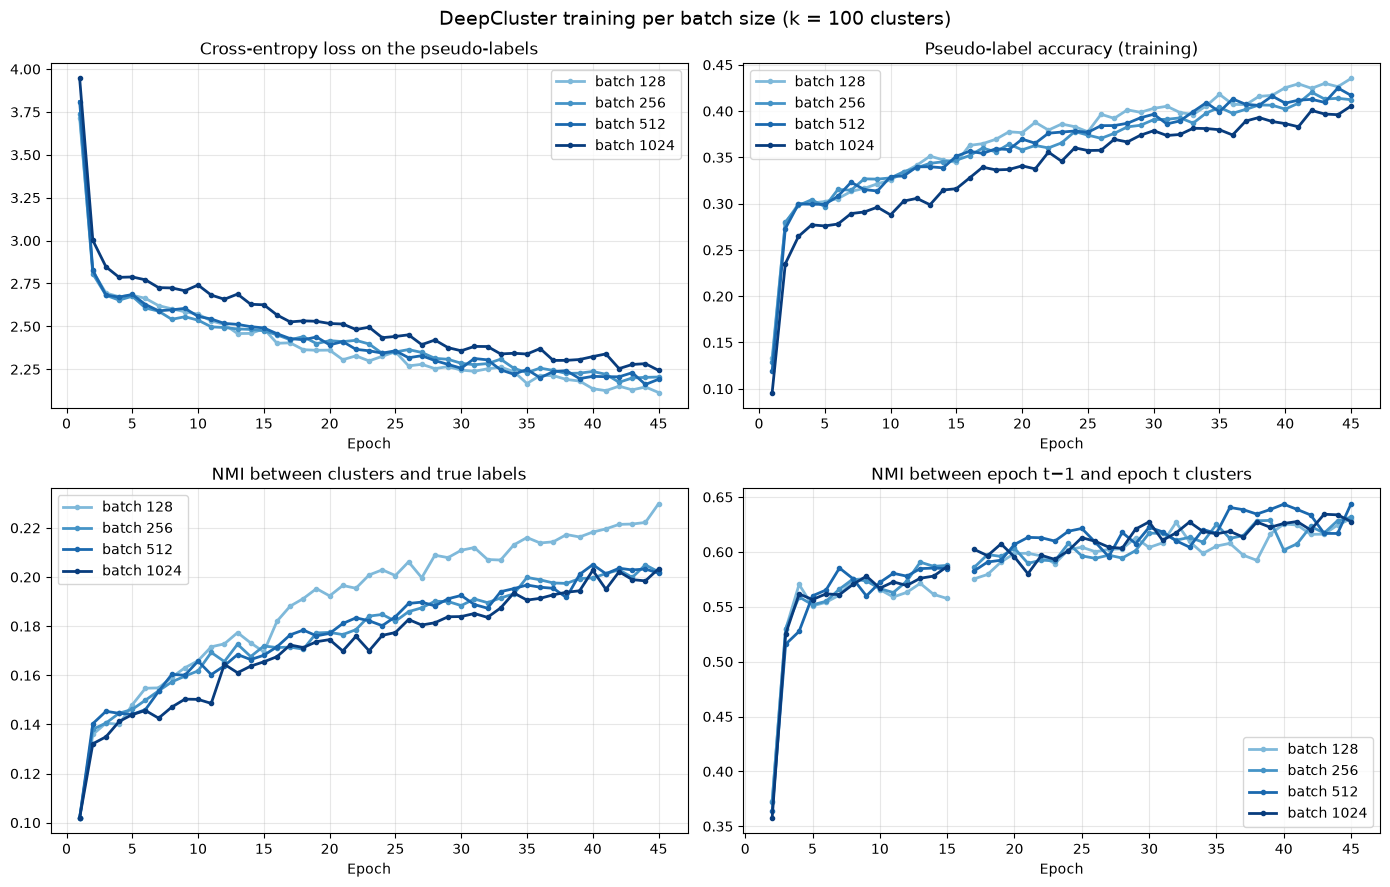

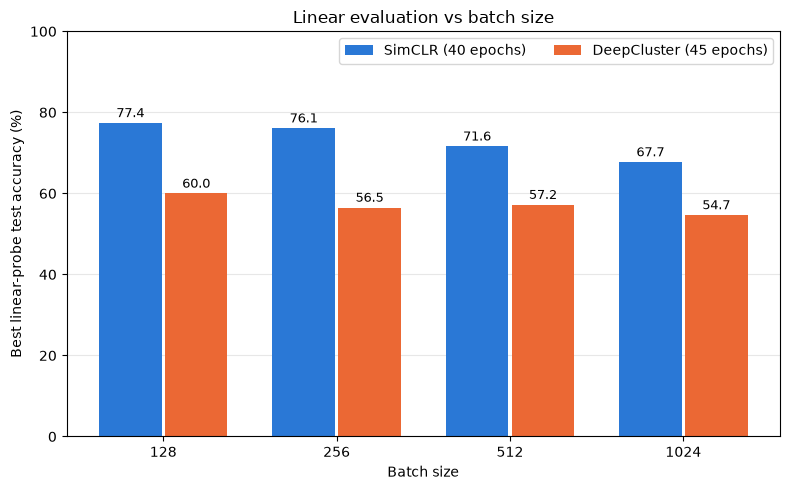

4 finished batch sizes; figures saved in results/deepcluster/


In [43]:
# DeepCluster results: training curves per batch size, and linear-probe accuracy next to SimCLR's.
# Plots are shown here, saved as PNGs, and logged to a W&B summary run.
dc_results = load_dc_results()
dc_runs = dict(sorted((r['batch_size'], r) for r in dc_results.values()))
bs_colors = dict(zip(DC_BATCH_SIZES, plt.cm.Blues(np.linspace(0.45, 0.95, len(DC_BATCH_SIZES)))))  # small → large: light → dark

# SimCLR batch-size results (40 epochs, same batch sizes), from the W&B summary that cell 40 reads
simclr_summary_path = 'wandb/run-20261029_012321-ll1rw0m7/files/wandb-summary.json'
simclr_bs_acc = {}
if os.path.exists(simclr_summary_path):
    with open(simclr_summary_path) as f:
        simclr_summary = json.load(f)
    simclr_bs_acc = {bs: simclr_summary[f'batch_size_{bs}/best_test_acc'] for bs in DC_BATCH_SIZES
                     if f'batch_size_{bs}/best_test_acc' in simclr_summary}
else:
    print(f'SimCLR batch-size results not found at {simclr_summary_path}; plotting DeepCluster only')

print(f'{"batch":>6} {"LR":>6} {"DeepCluster acc":>16} {"SimCLR acc":>11} {"final NMI":>10} {"minutes":>8}')
for bs, r in dc_runs.items():
    simclr_acc = f'{simclr_bs_acc[bs] * 100:.2f}%' if bs in simclr_bs_acc else '—'
    print(f'{bs:>6} {r["lr"]:>6g} {r["best_test_acc"] * 100:>15.2f}% {simclr_acc:>11} '
          f'{r["final_nmi_labels"]:>10.3f} {r["train_minutes"]:>8.1f}')

# --- Training curves: one line per batch size
panels = [('loss', 'Cross-entropy loss on the pseudo-labels'),
          ('pseudo_label_acc', 'Pseudo-label accuracy (training)'),
          ('nmi_labels', 'NMI between clusters and true labels'),
          ('nmi_previous', 'NMI between epoch t−1 and epoch t clusters')]

def epochs_axis(key, values):
    start = 2 if key == 'nmi_previous' else 1   # nmi_previous needs a previous clustering
    return list(range(start, start + len(values)))

fig_curves, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (key, title) in zip(axes.flat, panels):
    for bs, r in dc_runs.items():
        values = r['history'][key]
        ax.plot(epochs_axis(key, values), values, marker='.', linewidth=2, color=bs_colors[bs],
                label=f'batch {bs}')
    ax.set_title(title); ax.set_xlabel('Epoch'); ax.grid(True, alpha=0.3)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    if dc_runs:
        ax.legend()
fig_curves.suptitle(f'DeepCluster training per batch size (k = {DC_NUM_CLUSTERS} clusters)', fontsize=14)
fig_curves.tight_layout()

# --- Linear-probe accuracy vs batch size: SimCLR and DeepCluster side by side
fig_acc, ax = plt.subplots(figsize=(8, 5))
positions = np.arange(len(DC_BATCH_SIZES))
width = 0.38
methods = [('SimCLR (40 epochs)', simclr_bs_acc, '#2a78d6'),
           (f'DeepCluster ({DC_EPOCHS} epochs)', {bs: r['best_test_acc'] for bs, r in dc_runs.items()}, '#eb6834')]
for i, (method, accs, color) in enumerate(methods):
    shown = [j for j, bs in enumerate(DC_BATCH_SIZES) if bs in accs]
    bars = ax.bar(positions[shown] + (i - 0.5) * width, [accs[DC_BATCH_SIZES[j]] * 100 for j in shown],
                  width * 0.95, color=color, label=method)
    ax.bar_label(bars, fmt='%.1f', padding=2, fontsize=9)
ax.set_xticks(positions, [str(bs) for bs in DC_BATCH_SIZES])
ax.set_xlabel('Batch size'); ax.set_ylabel('Best linear-probe test accuracy (%)')
ax.set_title('Linear evaluation vs batch size'); ax.set_ylim(0, 100)
ax.grid(True, axis='y', alpha=0.3); ax.set_axisbelow(True); ax.legend(loc='upper right', ncol=2)
fig_acc.tight_layout()

for fig, fname in [(fig_curves, 'training_curves.png'), (fig_acc, 'accuracy_vs_batch_size.png')]:
    fig.savefig(os.path.join(DC_FIG_DIR, fname), dpi=120)

# --- W&B summary run: result table, interactive charts and the figures above
close_wandb_run()
summary_run = wandb.init(project=DC_WANDB_PROJECT, group='summary', name='deepcluster-summary',
                         config={'epochs': DC_EPOCHS, 'batch_sizes': list(dc_runs), 'num_clusters': DC_NUM_CLUSTERS})
results_table = wandb.Table(
    columns=['batch_size', 'lr', 'deepcluster_best_acc (%)', 'deepcluster_final_acc (%)',
             'simclr_best_acc (%)', 'final_nmi_labels', 'train_minutes'],
    data=[[bs, r['lr'], r['best_test_acc'] * 100, r['final_test_acc'] * 100,
           simclr_bs_acc[bs] * 100 if bs in simclr_bs_acc else None, r['final_nmi_labels'], r['train_minutes']]
          for bs, r in dc_runs.items()],
)
charts = {'results_table': results_table, 'training_curves': wandb.Image(fig_curves),
          'accuracy_vs_batch_size_figure': wandb.Image(fig_acc)}
if dc_runs:
    acc_table = wandb.Table(columns=['batch_size', 'best_test_acc (%)'],
                            data=[[str(bs), r['best_test_acc'] * 100] for bs, r in dc_runs.items()])
    charts['accuracy_vs_batch_size'] = wandb.plot.bar(acc_table, 'batch_size', 'best_test_acc (%)',
                                                      title='DeepCluster: best linear-probe accuracy per batch size')
    for key, title in panels:
        charts[f'{key}_vs_epoch'] = wandb.plot.line_series(
            xs=[epochs_axis(key, r['history'][key]) for r in dc_runs.values()],
            ys=[r['history'][key] for r in dc_runs.values()],
            keys=[f'batch {bs}' for bs in dc_runs], title=title, xname='epoch')
summary_run.log(charts)
summary_run.finish()

plt.show()
print(f'{len(dc_runs)} finished batch sizes; figures saved in {DC_FIG_DIR}/')

deepcluster_bs256: 100 non-empty clusters, sizes 155–898, overall purity 42.7%


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


overall_purity,0.427


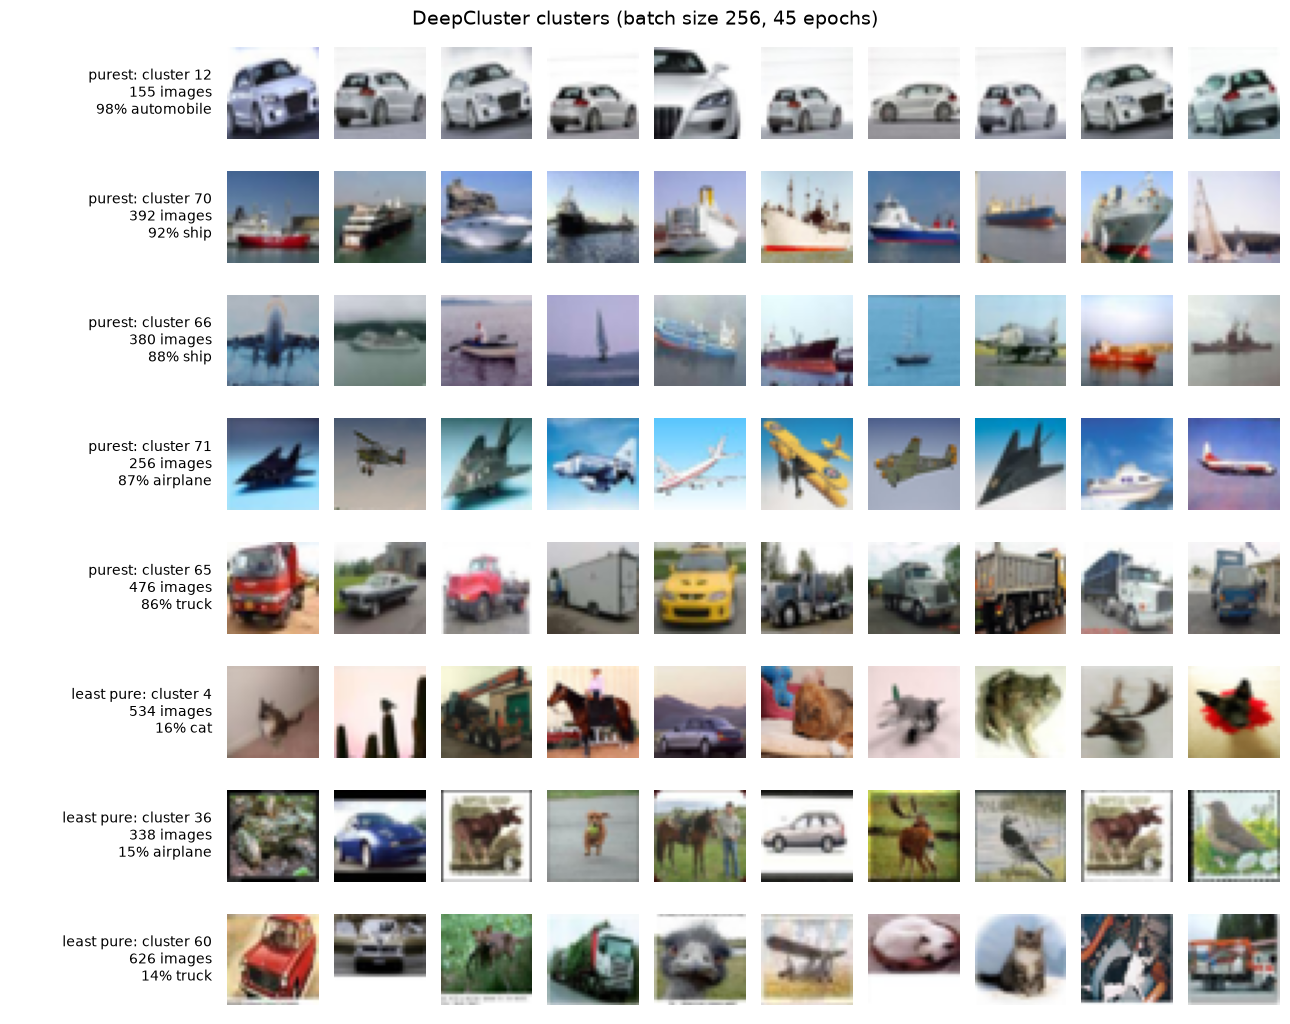

In [44]:
# What do DeepCluster's clusters contain? Training images from the final clustering of one model:
# its purest clusters and its least pure ones. Purity = share of the cluster's most common
# CIFAR-10 class. The true labels are only used here, never for training.
VIS_BATCH_SIZE = 256
vis_name = f'deepcluster_bs{VIS_BATCH_SIZE}'
checkpoint = torch.load(os.path.join(DC_CKPT_DIR, f'{vis_name}.pt'), map_location='cpu')
assignments = checkpoint['cluster_assignments']

sizes = torch.bincount(assignments, minlength=DC_NUM_CLUSTERS)
class_counts = torch.bincount(assignments * 10 + train_y, minlength=DC_NUM_CLUSTERS * 10).view(DC_NUM_CLUSTERS, 10)
majority_count, majority_class = class_counts.max(dim=1)
purity = majority_count / sizes.clamp(min=1)
print(f'{vis_name}: {(sizes > 0).sum().item()} non-empty clusters, sizes {sizes[sizes > 0].min().item()}'
      f'–{sizes.max().item()}, overall purity {majority_count.sum().item() / len(assignments):.1%}')

ranked = (sizes >= 20).nonzero().flatten()          # skip tiny clusters
ranked = ranked[purity[ranked].argsort(descending=True)].tolist()
shown = [('purest', c) for c in ranked[:5]] + [('least pure', c) for c in ranked[5:][-3:]]

n_images = 10
fig_clusters, axes = plt.subplots(len(shown), n_images + 1, figsize=(13, 1.3 * len(shown)),
                                  gridspec_kw={'width_ratios': [2.2] + [1] * n_images})
generator = torch.Generator().manual_seed(0)
for row, (kind, c) in enumerate(shown):
    members = (assignments == c).nonzero().flatten()
    picks = members[torch.randperm(len(members), generator=generator)[:n_images]].tolist()
    axes[row, 0].text(1.0, 0.5, f'{kind}: cluster {c}\n{sizes[c].item()} images\n'
                      f'{purity[c].item():.0%} {label_names[majority_class[c].item()]}',
                      ha='right', va='center', fontsize=10, transform=axes[row, 0].transAxes)
    for col, ax in enumerate(axes[row]):
        ax.axis('off')
        if 1 <= col <= len(picks):
            ax.imshow(train_x[picks[col - 1]].permute(1, 2, 0).cpu().numpy())
fig_clusters.suptitle(f'DeepCluster clusters (batch size {VIS_BATCH_SIZE}, '
                      f'{checkpoint["config"]["epochs"]} epochs)', fontsize=14)
fig_clusters.tight_layout()
fig_clusters.savefig(os.path.join(DC_FIG_DIR, f'clusters_bs{VIS_BATCH_SIZE}.png'), dpi=120)

close_wandb_run()
clusters_run = wandb.init(project=DC_WANDB_PROJECT, group='summary', name=f'clusters_bs{VIS_BATCH_SIZE}',
                          config={'batch_size': VIS_BATCH_SIZE, 'num_clusters': DC_NUM_CLUSTERS})
clusters_run.log({'clusters': wandb.Image(fig_clusters)})
clusters_run.summary['overall_purity'] = majority_count.sum().item() / len(assignments)
clusters_run.finish()
plt.show()

## DeepCluster Augmentation Experiments (same as SimCLR's)

The same experiments as SimCLR's augmentation experiments above, now with DeepCluster, so the two methods can be compared configuration by configuration:

- **A — Composition:** random crop, color distortion, cutout and rotation, applied individually and in pairs. Horizontal flip is always on.
- **B — Color distortion strength:** crop + color with s ∈ {0, 0.25, 0.5, 1.0}. s = 0.5 is the crop + color run from A, so it is reused.
- **D — Why color matters:** without color distortion, do DeepCluster's clusters simply group images by color? Each run's final clusters are compared (NMI) with a k-means clustering of the images' raw color histograms, and with the true labels.

The augmentation pipelines are exactly SimCLR's (`build_aug_pipeline` from the SimCLR experiments: crop area 0.08–1, jitter (0.8s, 0.8s, 0.8s, 0.2s) with probability 0.8, grayscale with probability 0.2, square cutout, rotation by 90°, 180° or 270°). DeepCluster applies them to the single view it trains on. Clustering always uses the un-augmented images, so augmentation decides which differences the network must ignore to predict an image's cluster.

Every run uses the same budget as the SimCLR augmentation runs (20 epochs, batch size 256) with the DeepCluster recipe of section 6: k = 100 clusters re-computed every epoch, SGD with LR 0.05, momentum 0.9 and weight decay 1e-5, and the same linear probe on frozen features. All runs start from the same initialisation.

Each configuration is logged as its own W&B run in the project `deepcluster-augmentations` (per step and per epoch, plus NMI with the true labels and with the previous epoch's clusters). Its weights, final clusters and results are saved under `checkpoints/deepcluster_augmentations/`, and finished configurations are skipped when a cell is re-run, so an interrupted experiment continues where it stopped. The cells below need the SimCLR augmentation setup cell and the DeepCluster setup cell to have been run (neither trains anything).

In [45]:
import os, time
from itertools import combinations
import wandb
from sklearn.metrics import normalized_mutual_info_score

# ---- DeepCluster augmentation runs: SimCLR's augmentation configurations (build_aug_pipeline,
# AUG_* settings) trained with the DeepCluster recipe (DeepClusterModel, train_deepcluster, DC_*) ----
DC_AUG_EPOCHS = AUG_EPOCHS              # 20, the same budget as the SimCLR augmentation runs
DC_AUG_BATCH_SIZE = AUG_BATCH_SIZE      # 256
DC_AUG_LR = deepcluster_lr(DC_AUG_BATCH_SIZE)
DC_AUG_WANDB_PROJECT = 'deepcluster-augmentations'
DC_AUG_CKPT_DIR = 'checkpoints/deepcluster_augmentations'
DC_AUG_FIG_DIR = 'results/deepcluster_augmentations'
DC_AUG_RESULTS_PATH = os.path.join(DC_AUG_CKPT_DIR, 'results.json')
os.makedirs(DC_AUG_CKPT_DIR, exist_ok=True)
os.makedirs(DC_AUG_FIG_DIR, exist_ok=True)


def train_deepcluster_with_transform(model, transform, batch_size, epochs, run=None):
    """train_deepcluster with a different training augmentation. It reads the global
    dc_transform, so that is swapped for this run and restored afterwards."""
    global dc_transform
    default_dc_transform = dc_transform
    dc_transform = transform
    try:
        return train_deepcluster(model, batch_size, epochs, run)
    finally:
        dc_transform = default_dc_transform


def run_dc_aug_config(name, augs, s=AUG_COLOR_S, experiment='A'):
    """Pre-train DeepCluster with one augmentation configuration (the same ones as run_aug_config),
    run the linear probe, save the weights, final clusters and results, and log everything to W&B.
    Skips finished configs."""
    ckpt_path = os.path.join(DC_AUG_CKPT_DIR, f'{name}.pt')
    done = load_dc_results(DC_AUG_RESULTS_PATH)
    if name in done and os.path.exists(ckpt_path):
        print(f'{name}: already done (best test acc {done[name]["best_test_acc"] * 100:.2f}%), skipping')
        return done[name]

    config = dict(name=name, experiment=experiment, augmentations=[a for a in AUG_NAMES if a in augs],
                  color_strength=s if 'color' in augs else None, epochs=DC_AUG_EPOCHS,
                  batch_size=DC_AUG_BATCH_SIZE, num_clusters=DC_NUM_CLUSTERS, pca_dim=DC_PCA_DIM,
                  kmeans_iters=DC_KMEANS_ITERS, optimizer='SGD', lr=DC_AUG_LR, momentum=DC_MOMENTUM,
                  weight_decay=DC_WEIGHT_DECAY, crop_scale=list(AUG_CROP_SCALE),
                  linear_eval_epochs=DC_LINEAR_EVAL_EPOCHS, seed=DC_SEED)
    print(f'\n{"=" * 60}\nDeepCluster {name}: {" + ".join(config["augmentations"])} (+ flip)'
          + (f', s = {s}' if 'color' in augs else '') + f'\n{"=" * 60}')

    close_wandb_run()
    run = wandb.init(project=DC_AUG_WANDB_PROJECT, group=f'experiment-{experiment}', name=name, config=config)
    run.define_metric('global_step')
    run.define_metric('train/*', step_metric='global_step')
    run.define_metric('epoch')
    run.define_metric('epoch/*', step_metric='epoch')
    try:
        torch.manual_seed(DC_SEED)
        model = DeepClusterModel().to(device)
        start = time.time()
        history, assignments = train_deepcluster_with_transform(
            model, build_aug_pipeline(augs, s), DC_AUG_BATCH_SIZE, DC_AUG_EPOCHS, run)
        train_minutes = (time.time() - start) / 60
        final_nmi = normalized_mutual_info_score(train_y.numpy(), assignments.cpu().numpy())

        model.eval()
        _, best_acc, final_acc = train_linear_classifier(
            model.encoder, train_loader, test_loader, feature_dim=512, num_classes=10,
            epochs=DC_LINEAR_EVAL_EPOCHS, lr=0.3, return_final_accuracy=True,
        )
        result = dict(config, history=history, best_test_acc=best_acc, final_test_acc=final_acc,
                      final_nmi_labels=final_nmi, train_minutes=train_minutes)
        torch.save({'config': config, 'model_state_dict': model.state_dict(),
                    'cluster_assignments': assignments.cpu(), 'history': history,
                    'best_test_acc': best_acc, 'final_test_acc': final_acc}, ckpt_path)
        save_dc_result(name, result, DC_AUG_RESULTS_PATH)
        run.summary.update({'best_test_acc': best_acc, 'final_test_acc': final_acc,
                            'final_nmi_labels': final_nmi, 'train_minutes': train_minutes})
        print(f'{name}: best test acc {best_acc * 100:.2f}%, final NMI(labels) {final_nmi:.3f} '
              f'({train_minutes:.1f} min), weights saved to {ckpt_path}')
    finally:
        try:
            run.finish()
        except Exception:
            pass   # wandb was stopped by an interrupt; close_wandb_run() recovers next time
    return result

In [ ]:
# DeepCluster experiment A — every augmentation alone and in pairs (the same 10 configurations as SimCLR's A)
dc_aug_combos_A = [(a,) for a in AUG_NAMES] + list(combinations(AUG_NAMES, 2))
print(f'{len(dc_aug_combos_A)} configurations: {["+".join(c) for c in dc_aug_combos_A]}')

for augs in dc_aug_combos_A:
    run_dc_aug_config('A_' + '+'.join(augs), augs, experiment='A')

10 configurations: ['crop', 'color', 'cutout', 'rotate', 'crop+color', 'crop+cutout', 'crop+rotate', 'color+cutout', 'color+rotate', 'cutout+rotate']

DeepCluster A_crop: crop (+ flip)


Feature dimension (before FC): 512


Epochs:   0%|          | 0/20 [00:00<?, ?it/s]

Epoch 1/20:   0%|          | 0/195 [00:00<?, ?it/s]

  Epoch [1/20]  Loss: 3.6290  Pseudo-label acc: 0.158  NMI(labels): 0.102  LR: 0.0500


...

  Epoch [5/20]  Loss: 1.4048  Pseudo-label acc: 0.599  NMI(labels): 0.134  LR: 0.0500


Epoch 6/20:   0%|          | 0/195 [00:00<?, ?it/s]

Epoch 7/20:   0%|          | 0/195 [00:00<?, ?it/s]

Epoch 8/20:   0%|          | 0/195 [00:00<?, ?it/s]

Epoch 9/20:   0%|          | 0/195 [00:00<?, ?it/s]

In [ ]:
# DeepCluster experiment B — color distortion strength with crop + color (the same strengths as SimCLR's B)
for s in AUG_B_STRENGTHS:
    if s == AUG_COLOR_S:
        print(f's = {s}: same configuration as A_crop+color, reusing that run')
        continue
    run_dc_aug_config(f'B_crop+color_s{s}', ('crop', 'color'), s=s, experiment='B')

In [ ]:
# Results of DeepCluster experiments A and B next to SimCLR's: plots here, saved as PNGs,
# and logged to a W&B summary run
dc_aug_results = load_dc_results(DC_AUG_RESULTS_PATH)
simclr_aug_results = load_aug_results()   # SimCLR's experiments A and B: same configurations and epochs
aug_methods = [('SimCLR', simclr_aug_results, '#2a78d6'), ('DeepCluster', dc_aug_results, '#eb6834')]


def config_result(results, augs, s=AUG_COLOR_S):
    """Finished run for a set of augmentations (B's s = 0.5 run is A's crop+color)."""
    if 'color' in augs and s != AUG_COLOR_S:
        return results.get(f'B_crop+color_s{s}')
    return results.get('A_' + '+'.join(a for a in AUG_NAMES if a in augs))


print(f'{"configuration":<22} {"DeepCluster acc":>16} {"SimCLR acc":>11} {"final NMI":>10} {"minutes":>8}')
for name, r in dc_aug_results.items():
    simclr_acc = f'{simclr_aug_results[name]["best_test_acc"] * 100:.2f}%' if name in simclr_aug_results else '—'
    print(f'{name:<22} {r["best_test_acc"] * 100:>15.2f}% {simclr_acc:>11} '
          f'{r["final_nmi_labels"]:>10.3f} {r["train_minutes"]:>8.1f}')

# --- A: accuracy heatmaps, SimCLR and DeepCluster on one color scale
#     (diagonal = single augmentation, off-diagonal = pair)
n_augs = len(AUG_NAMES)
acc_matrices = {}
for method, results, _ in aug_methods:
    acc_matrices[method] = np.full((n_augs, n_augs), np.nan)
    for i, a in enumerate(AUG_NAMES):
        for j, b in enumerate(AUG_NAMES):
            r = config_result(results, {a, b})
            if r is not None:
                acc_matrices[method][i, j] = r['best_test_acc'] * 100
all_accs = np.concatenate([m[np.isfinite(m)] for m in acc_matrices.values()])
vmin, vmax = (all_accs.min(), all_accs.max()) if len(all_accs) else (0, 100)

fig_a, axes = plt.subplots(1, 2, figsize=(13, 5.5), layout='constrained')
heat_cmap = plt.get_cmap('Blues').copy()
heat_cmap.set_bad('lightgray')   # configurations without a result yet
for ax, (method, acc_matrix) in zip(axes, acc_matrices.items()):
    im = ax.imshow(np.ma.masked_invalid(acc_matrix), cmap=heat_cmap, vmin=vmin, vmax=vmax)
    ax.set_xticks(range(n_augs), AUG_NAMES); ax.set_yticks(range(n_augs), AUG_NAMES)
    ax.set_xlabel('2nd transformation'); ax.set_ylabel('1st transformation')
    for i in range(n_augs):
        for j in range(n_augs):
            acc = acc_matrix[i, j]
            if np.isnan(acc):
                ax.text(j, i, '—', ha='center', va='center', color='dimgray', fontsize=12)
            else:
                dark_cell = (acc - vmin) / max(vmax - vmin, 1e-9) > 0.55
                ax.text(j, i, f'{acc:.1f}', ha='center', va='center', fontsize=12,
                        color='white' if dark_cell else '#0b0b0b')
    ax.set_title(method)
fig_a.colorbar(im, ax=axes, label='Linear-probe test accuracy (%)', shrink=0.9)
fig_a.suptitle(f'A: single augmentations (diagonal) and pairs, {DC_AUG_EPOCHS} epochs each', fontsize=14)

# --- B: accuracy vs color strength, both methods
b_points = {}
fig_b, ax = plt.subplots(figsize=(7, 5))
for method, results, color in aug_methods:
    points = [(s, config_result(results, {'crop', 'color'}, s)) for s in AUG_B_STRENGTHS]
    points = [(s, r['best_test_acc'] * 100) for s, r in points if r is not None]
    if not points:
        continue
    b_points[method] = points
    ax.plot([s for s, _ in points], [acc for _, acc in points], 'o-', linewidth=2, markersize=8,
            color=color, label=method)
    for s, acc in points:   # SimCLR's labels above its line, DeepCluster's below
        ax.annotate(f'{acc:.1f}%', (s, acc), textcoords='offset points', ha='center', fontsize=9,
                    xytext=(0, 10) if method == 'SimCLR' else (0, -16))
ax.set_xticks(AUG_B_STRENGTHS); ax.margins(y=0.15)
ax.set_xlabel('Color distortion strength s'); ax.set_ylabel('Best linear-probe test accuracy (%)')
ax.set_title('B: crop + color, varying color strength'); ax.grid(True, alpha=0.3)
if b_points:
    ax.legend()
fig_b.tight_layout()

# --- DeepCluster training curves for every run: loss, pseudo-label accuracy and NMI per epoch
panels = [('loss', 'Cross-entropy loss on the pseudo-labels'),
          ('pseudo_label_acc', 'Pseudo-label accuracy (training)'),
          ('nmi_labels', 'NMI between clusters and true labels')]
a_runs = {k.removeprefix('A_'): v for k, v in dc_aug_results.items() if v['experiment'] == 'A'}
b_runs = {s: config_result(dc_aug_results, {'crop', 'color'}, s) for s in AUG_B_STRENGTHS}
b_runs = {s: r for s, r in b_runs.items() if r is not None}
strength_colors = dict(zip(AUG_B_STRENGTHS, plt.cm.Blues(np.linspace(0.45, 0.95, len(AUG_B_STRENGTHS)))))
fig_curves, axes = plt.subplots(2, 3, figsize=(18, 10))
for row, (experiment, runs) in enumerate([('A', a_runs), ('B', b_runs)]):
    for ax, (key, title) in zip(axes[row], panels):
        for label, r in runs.items():
            values = r['history'][key]
            style = dict(color=strength_colors[label], label=f's = {label}') if experiment == 'B' else dict(label=label)
            ax.plot(range(1, len(values) + 1), values, marker='.', linewidth=2, **style)
        ax.set_title(f'{experiment}: {title}'); ax.set_xlabel('Epoch'); ax.grid(True, alpha=0.3)
        ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    if runs:
        axes[row, 0].legend(fontsize=8, ncol=2)
fig_curves.suptitle(f'DeepCluster training per augmentation configuration (k = {DC_NUM_CLUSTERS} clusters)', fontsize=14)
fig_curves.tight_layout()

for fig, fname in [(fig_a, 'A_heatmap.png'), (fig_b, 'B_color_strength.png'), (fig_curves, 'training_curves.png')]:
    fig.savefig(os.path.join(DC_AUG_FIG_DIR, fname), dpi=120)

# --- W&B summary run: result table, interactive charts and the figures above
close_wandb_run()
summary_run = wandb.init(project=DC_AUG_WANDB_PROJECT, group='summary', name='deepcluster-augmentation-summary',
                         config={'epochs': DC_AUG_EPOCHS, 'batch_size': DC_AUG_BATCH_SIZE, 'lr': DC_AUG_LR,
                                 'num_clusters': DC_NUM_CLUSTERS})
results_table = wandb.Table(
    columns=['name', 'experiment', 'augmentations', 'color_strength', 'deepcluster_best_acc (%)',
             'deepcluster_final_acc (%)', 'simclr_best_acc (%)', 'final_nmi_labels', 'train_minutes'],
    data=[[k, v['experiment'], ' + '.join(v['augmentations']), v['color_strength'], v['best_test_acc'] * 100,
           v['final_test_acc'] * 100,
           simclr_aug_results[k]['best_test_acc'] * 100 if k in simclr_aug_results else None,
           v['final_nmi_labels'], v['train_minutes']] for k, v in dc_aug_results.items()],
)
charts = {'results_table': results_table, 'A_heatmaps': wandb.Image(fig_a),
          'B_color_strength_figure': wandb.Image(fig_b), 'training_curves': wandb.Image(fig_curves)}
if a_runs:
    a_table = wandb.Table(columns=['configuration', 'best_test_acc (%)'],
                          data=[[k, v['best_test_acc'] * 100] for k, v in a_runs.items()])
    charts['A_accuracy'] = wandb.plot.bar(a_table, 'configuration', 'best_test_acc (%)',
                                          title='A: DeepCluster best linear-probe accuracy per configuration')
    for key, title in panels:
        charts[f'A_{key}_vs_epoch'] = wandb.plot.line_series(
            xs=[list(range(1, len(v['history'][key]) + 1)) for v in a_runs.values()],
            ys=[v['history'][key] for v in a_runs.values()],
            keys=list(a_runs), title=f'A: {title}', xname='epoch')
if b_points:
    charts['B_accuracy_vs_strength'] = wandb.plot.line_series(
        xs=[[s for s, _ in points] for points in b_points.values()],
        ys=[[acc for _, acc in points] for points in b_points.values()],
        keys=list(b_points), title='B: best linear-probe accuracy vs color strength', xname='color strength s')
if b_runs:
    charts['B_loss_vs_epoch'] = wandb.plot.line_series(
        xs=[list(range(1, len(r['history']['loss']) + 1)) for r in b_runs.values()],
        ys=[r['history']['loss'] for r in b_runs.values()],
        keys=[f's = {s}' for s in b_runs], title='B: cross-entropy loss on the pseudo-labels', xname='epoch')
summary_run.log(charts)
summary_run.finish()

plt.show()
print(f'{len(dc_aug_results)} finished DeepCluster runs; figures saved in {DC_AUG_FIG_DIR}/')

In [ ]:
# DeepCluster experiment D — why color distortion matters. The network is trained to predict each
# image's cluster; without color distortion it can do that from the image's colors alone, so the
# clusters may end up grouping images by color. Each run's final clusters are compared (NMI) with a
# k-means clustering of the images' raw color histograms, and with the true labels.
COLOR_BINS = 4   # per channel: a 4 × 4 × 4 = 64-bin RGB histogram per image


@torch.no_grad()
def color_histograms(images, bins=COLOR_BINS):
    """Joint RGB histogram of each uint8 image, as fractions of its pixels."""
    q = images // (256 // bins)                                     # bin index per channel
    idx = ((q[:, 0].long() * bins + q[:, 1]) * bins + q[:, 2]).flatten(1)
    hist = torch.zeros(len(images), bins ** 3, device=images.device)
    hist.scatter_add_(1, idx, torch.ones_like(idx, dtype=hist.dtype))
    return hist / idx.shape[1]


torch.manual_seed(DC_SEED)
color_clusters, _ = kmeans(F.normalize(color_histograms(train_x).sqrt(), dim=1), DC_NUM_CLUSTERS)
color_clusters = color_clusters.cpu().numpy()
color_nmi_labels = normalized_mutual_info_score(train_y.numpy(), color_clusters)
print(f'k-means on color histograms alone (k = {DC_NUM_CLUSTERS}): NMI with true labels {color_nmi_labels:.3f}')

dc_aug_results = load_dc_results(DC_AUG_RESULTS_PATH)
final_clusters, d_rows = {}, []
for name, r in dc_aug_results.items():
    checkpoint = torch.load(os.path.join(DC_AUG_CKPT_DIR, f'{name}.pt'), map_location='cpu')
    final_clusters[name] = checkpoint['cluster_assignments']
    label = (name.removeprefix('A_') if r['experiment'] == 'A'
             else f'crop+color, s = {r["color_strength"]}')
    d_rows.append(dict(name=name, label=label,
                       color_distortion='color' in r['augmentations'] and r['color_strength'] > 0,
                       nmi_color=normalized_mutual_info_score(color_clusters, final_clusters[name].numpy()),
                       nmi_labels=r['final_nmi_labels']))
for row in d_rows:
    print(f'{row["label"]:<22} NMI with color clusters {row["nmi_color"]:.3f}   with labels {row["nmi_labels"]:.3f}')

# --- NMI of each run's clusters with the color-histogram clusters and with the true labels
with_color, without_color = '#1baf7a', '#a3a29d'
fig_d, axes = plt.subplots(1, 2, figsize=(14, 0.45 * len(d_rows) + 2), sharey=True)
y = np.arange(len(d_rows))
bar_colors = [with_color if row['color_distortion'] else without_color for row in d_rows]
for ax, key, title in [(axes[0], 'nmi_color', 'Agreement with color-histogram clusters'),
                       (axes[1], 'nmi_labels', 'Agreement with the true labels')]:
    values = [row[key] for row in d_rows]
    bars = ax.barh(y, values, height=0.7, color=bar_colors)
    ax.bar_label(bars, fmt='%.3f', padding=3, fontsize=9)
    ax.set_xlim(0, max(values + [color_nmi_labels], default=1) * 1.2)
    ax.set_title(title); ax.set_xlabel('NMI with the final DeepCluster clusters')
    ax.grid(True, axis='x', alpha=0.3); ax.set_axisbelow(True)
reference = axes[1].axvline(color_nmi_labels, color='#52514e', linestyle='--', linewidth=1.5,
                            label=f'color-histogram clusters vs true labels ({color_nmi_labels:.3f})')
axes[0].set_yticks(y, [row['label'] for row in d_rows]); axes[0].invert_yaxis()
fig_d.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=with_color, label='trained with color distortion'),
                      plt.Rectangle((0, 0), 1, 1, color=without_color, label='without color distortion'),
                      reference], loc='lower center', ncol=3, fontsize=10)
fig_d.suptitle('D: do the DeepCluster clusters follow color or the true labels?', fontsize=14)
fig_d.tight_layout(rect=(0, 0.06, 1, 1))   # room for the legend below the panels

# --- Example clusters of crop-only vs crop + color training (random clusters, same seed)
D_EXAMPLE_RUNS = [('A_crop', 'crop only'), ('A_crop+color', 'crop + color')]
D_EXAMPLE_RUNS = [(name, title) for name, title in D_EXAMPLE_RUNS if name in final_clusters]
N_CLUSTERS_SHOWN, N_IMAGES = 4, 10
fig_examples = None
if D_EXAMPLE_RUNS:
    n_rows = len(D_EXAMPLE_RUNS) * N_CLUSTERS_SHOWN
    fig_examples, axes = plt.subplots(n_rows, N_IMAGES + 1, figsize=(13, 1.3 * n_rows), squeeze=False,
                                      gridspec_kw={'width_ratios': [2.2] + [1] * N_IMAGES})
    generator = torch.Generator().manual_seed(0)
    for block, (name, title) in enumerate(D_EXAMPLE_RUNS):
        assignments = final_clusters[name]
        sizes = torch.bincount(assignments, minlength=DC_NUM_CLUSTERS)
        candidates = (sizes >= N_IMAGES).nonzero().flatten()
        shown = candidates[torch.randperm(len(candidates), generator=generator)[:N_CLUSTERS_SHOWN]].tolist()
        for k, c in enumerate(shown):
            row = block * N_CLUSTERS_SHOWN + k
            members = (assignments == c).nonzero().flatten()
            picks = members[torch.randperm(len(members), generator=generator)[:N_IMAGES]].tolist()
            majority = torch.bincount(train_y[members], minlength=10)
            axes[row, 0].text(1.0, 0.5, f'{title}: cluster {c}\n{sizes[c].item()} images\n'
                              f'{majority.max().item() / len(members):.0%} {label_names[majority.argmax().item()]}',
                              ha='right', va='center', fontsize=10, transform=axes[row, 0].transAxes)
            for col, ax in enumerate(axes[row]):
                ax.axis('off')
                if 1 <= col <= len(picks):
                    ax.imshow(train_x[picks[col - 1]].permute(1, 2, 0).cpu().numpy())
    fig_examples.suptitle('D: random DeepCluster clusters, trained without and with color distortion', fontsize=14)
    fig_examples.tight_layout()

figures = [(fig_d, 'D_color_clusters.png')] + ([(fig_examples, 'D_cluster_examples.png')] if fig_examples else [])
for fig, fname in figures:
    fig.savefig(os.path.join(DC_AUG_FIG_DIR, fname), dpi=120)

close_wandb_run()
d_run = wandb.init(project=DC_AUG_WANDB_PROJECT, group='experiment-D', name='D_color_clusters',
                   config={'color_bins': COLOR_BINS, 'num_clusters': DC_NUM_CLUSTERS})
d_table = wandb.Table(columns=['configuration', 'color_distortion', 'nmi_color_clusters', 'nmi_labels'],
                      data=[[row['label'], row['color_distortion'], row['nmi_color'], row['nmi_labels']]
                            for row in d_rows])
d_logs = {'D_nmi_table': d_table, 'D_color_clusters': wandb.Image(fig_d),
          'D_nmi_color_clusters': wandb.plot.bar(d_table, 'configuration', 'nmi_color_clusters',
                                                 title='D: NMI between the clusters and color-histogram clusters')}
if fig_examples:
    d_logs['D_cluster_examples'] = wandb.Image(fig_examples)
d_run.log(d_logs)
d_run.summary['color_histogram_nmi_labels'] = color_nmi_labels
d_run.finish()
plt.show()